# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.constants import VTI
from sharpelab_nb.thermometry import temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260714.2-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.024 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.10s
Sample:    1.149 K
Vaporizer: 0.925 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s


Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::24::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.mode.set('VOLT')
k_2400_tg.volt.set(0)
k_2400_tg.rangei.set(1e-6)
k_2400_tg.rangev.set(21)
k_2400_tg.volt.step = 0.005
k_2400_tg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.02s


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::1::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.mode.set('VOLT')
k_2400_bg.volt.set(0)
k_2400_bg.rangei.set(1e-6)
k_2400_bg.rangev.set(21)
k_2400_bg.volt.step = 0.005
k_2400_bg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.04s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -3.0, +3.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T2",  # drive injection contact (provided config)    # <-- validate
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4 (Rxx)",  # <-- validate
    "sr2": "B4-B5 (Rxx)",  # <-- validate
    "sr3": "T5-B6 (Rxy, Hall)",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T2", "drain": "B7",
    "sr1+": "T3", "sr1-": "T4",
    "sr2+": "B4", "sr2-": "B5",
    "sr3+": "T5", "sr3-": "B6",
}

# HERA — session start (2026-07-14) — QC0426

## HERA — session-start VERIFY closeout (read-only)

Gates A/B read green from the page: setup executed in this kernel with sane readbacks, SAFETIES committed [exec 10] matching the device card (TG ±3.0 V / BG ±4.5 V / Si ±50 V / |B| ≤ 8.0 T), and the thermometry worker's logfiles are advancing (checked on disk). This cell closes the remaining [VERIFY] items with live reads — magnet at 0 T + PS/output state, base T, DC205 at 0 V on RNGE 2, gates at 0, live validators, and the lock-in τ / filter-slope / sensitivity bring-up record (rig card: the run metadata does not capture τ, so this printout is where τ lives on disk this session).

No instrument writes. Runs in a few seconds. If all lines read as expected, the brief's VERIFY list is closed and the E1 grant ("go for autonomy") is yours to give.


In [15]:
# HERA — session-start VERIFY (read-only; no instrument writes)
print("--- magnet ---")
print(f"field (measured):     {magnet.field():+.4f} T   (expect ~0)")
print(f"persistent switch on: {magnet.persistent_switch_on()}   (expect True)")
print(f"output enabled:       {magnet.output_enabled()}   (expect True)")

print("--- thermometry (worker logfiles) ---")
print(f"T_sample:    {T_sample():.3f} K   (expect ~1.2-1.3 K)")
print(f"T_vaporizer: {T_vaporizer():.3f} K")

print("--- gates (all should be parked at 0) ---")
print(f"k_tg.volt:     {k_tg.volt():+.4f} V")
print(f"k_bg.volt:     {k_bg.volt():+.4f} V")
print(f"dc205.voltage: {dc205.voltage():+.4f} V   range code {dc205.voltage_range()} (need 2)   output {dc205.output()}")

print("--- committed validators (SAFETIES) ---")
print(f"k_tg.volt.vals:           {k_2400_tg.volt.vals}")
print(f"k_bg.volt.vals:           {k_2400_bg.volt.vals}")
print(f"dc205.smart_voltage.vals: {dc205.smart_voltage.vals}")
print(f"dc205.voltage.vals:       {dc205.voltage.vals}")
print(f"magnet.field.vals:        {magnet.field.vals}")

print("--- lock-in bring-up record (tau / slope / sens / amp / freq) ---")
for name, lia in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"{name}: tau={lia.time_constant()} s  slope={lia.filter_slope()} dB/oct  "
          f"sens={lia.sensitivity()}  amp={lia.amplitude()} V  "
          f"freq={lia.frequency():.3f} Hz  X={lia.X():+.3e}")


--- magnet ---
field (measured):     +0.0033 T   (expect ~0)
persistent switch on: True   (expect True)
output enabled:       True   (expect True)
--- thermometry (worker logfiles) ---
T_sample:    1.150 K   (expect ~1.2-1.3 K)
T_vaporizer: 0.926 K
--- gates (all should be parked at 0) ---
k_tg.volt:     +0.0000 V
k_bg.volt:     +0.0000 V
dc205.voltage: +0.0000 V   range code 2 (need 2)   output 1
--- committed validators (SAFETIES) ---
k_tg.volt.vals:           <Numbers -3.0<=v<=3.0>
k_bg.volt.vals:           <Numbers -4.5<=v<=4.5>
dc205.smart_voltage.vals: <Numbers -50.0<=v<=50.0>
dc205.voltage.vals:       <Numbers -50.0<=v<=50.0>
magnet.field.vals:        <Numbers -8.0<=v<=8.0>
--- lock-in bring-up record (tau / slope / sens / amp / freq) ---
sr0: tau=0.3 s  slope=24 dB/oct  sens=0.005  amp=0.004 V  freq=13.142 Hz  X=-4.987e-03
sr1: tau=0.3 s  slope=24 dB/oct  sens=2e-05  amp=0.5 V  freq=13.142 Hz  X=+8.057e-06
sr2: tau=0.3 s  slope=24 dB/oct  sens=2e-05  amp=0.004 V  freq=13.142 Hz

## HERA — Gate C: liveness check (`gate-current-sanity-check`)

First-session branch — no designated references, so this is a liveness-and-gross-safety pass judged on its own terms, per `device-init/gate-current-sanity-check.md`. Four legs, each its own run/file: TG 0→+3 V, TG 0→−3 V, BG 0→+4.5 V, BG 0→−4.5 V (endpoints = the committed SAFETIES limits; other gate parked at 0). `nplci=10` on both Keithleys for pA-resolution gate-current readback; the reset cell below undoes it.

**Si gate is excluded**: the DC205 has no current readback so a Si leg has no leakage watch; Si stays at 0 V for the D ≈ 0 campaign (it is a contact-doping gate only, screened from the channel by the graphite BG).

**What to watch, per leg (live plots):** lock-in X nonzero and smoothly varying = alive; swept gate current stays in pA on the capacitive charging slope = safe; parked gate current at floor = no cross-gate path. A gross turn-up off the charging slope → interrupt the cell (the `finally` parks the gate) and we stop-and-report.

**Cost:** 251 pts × 1 s delay ≈ 5–6 min/leg incl. readback overhead + ~1 min gate ramp-back each → **~25–30 min total**. VERIFY note: sr0 sits at ~99% of its 5 mV sensitivity at gates 0 (full 5 nA flowing); if it rails during the legs that is a sensitivity artifact, not a device problem — the current channel railing high is the healthy direction.

Preconditions asserted in-cell: T_sample < 2 K, |B| < 0.05 T, all gates at 0.


precheck: T_sample = 1.150 K (expect < 2), B = +0.0032 T (expect ~0), Vtg = +0.000, Vbg = +0.000, Vsi = +0.000


2026-07-14 20:52:49,118 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 20:52:49,639 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 20:52:49,662 [INFO] Starting sweep with ID 0


2026-07-14 20:52:49,662 [INFO] Minimum duration 0h 4m 11s


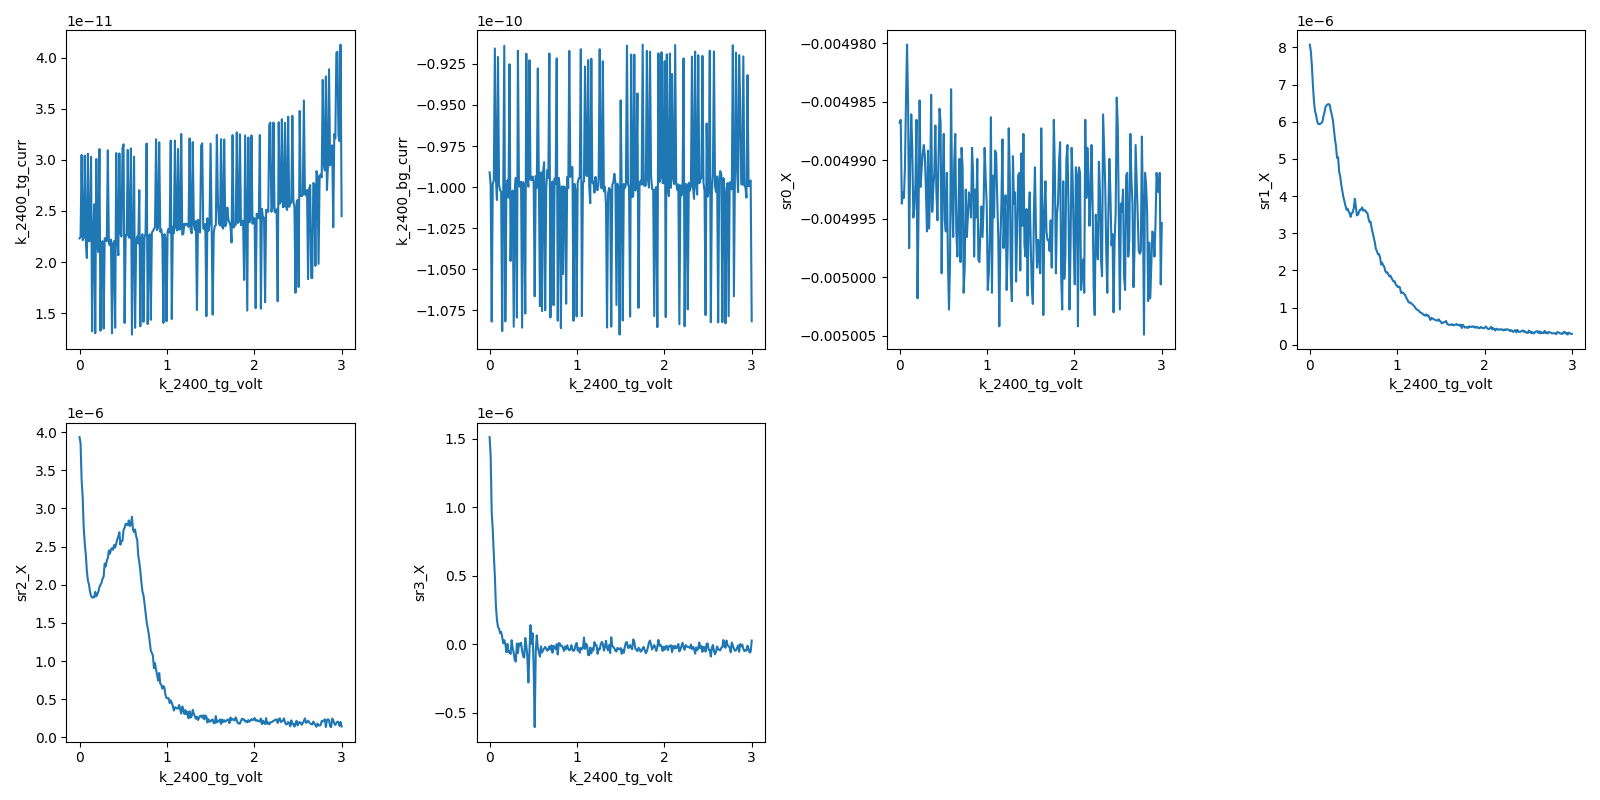

2026-07-14 21:01:41,402 [INFO] Completed in 0h 8m 51s


2026-07-14 21:01:41,402 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\0\data.tsv.gz


2026-07-14 21:01:41,910 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-14 21:01:46,219 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 21:01:46,734 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 21:01:46,748 [INFO] Starting sweep with ID 1


2026-07-14 21:01:46,748 [INFO] Minimum duration 0h 4m 11s


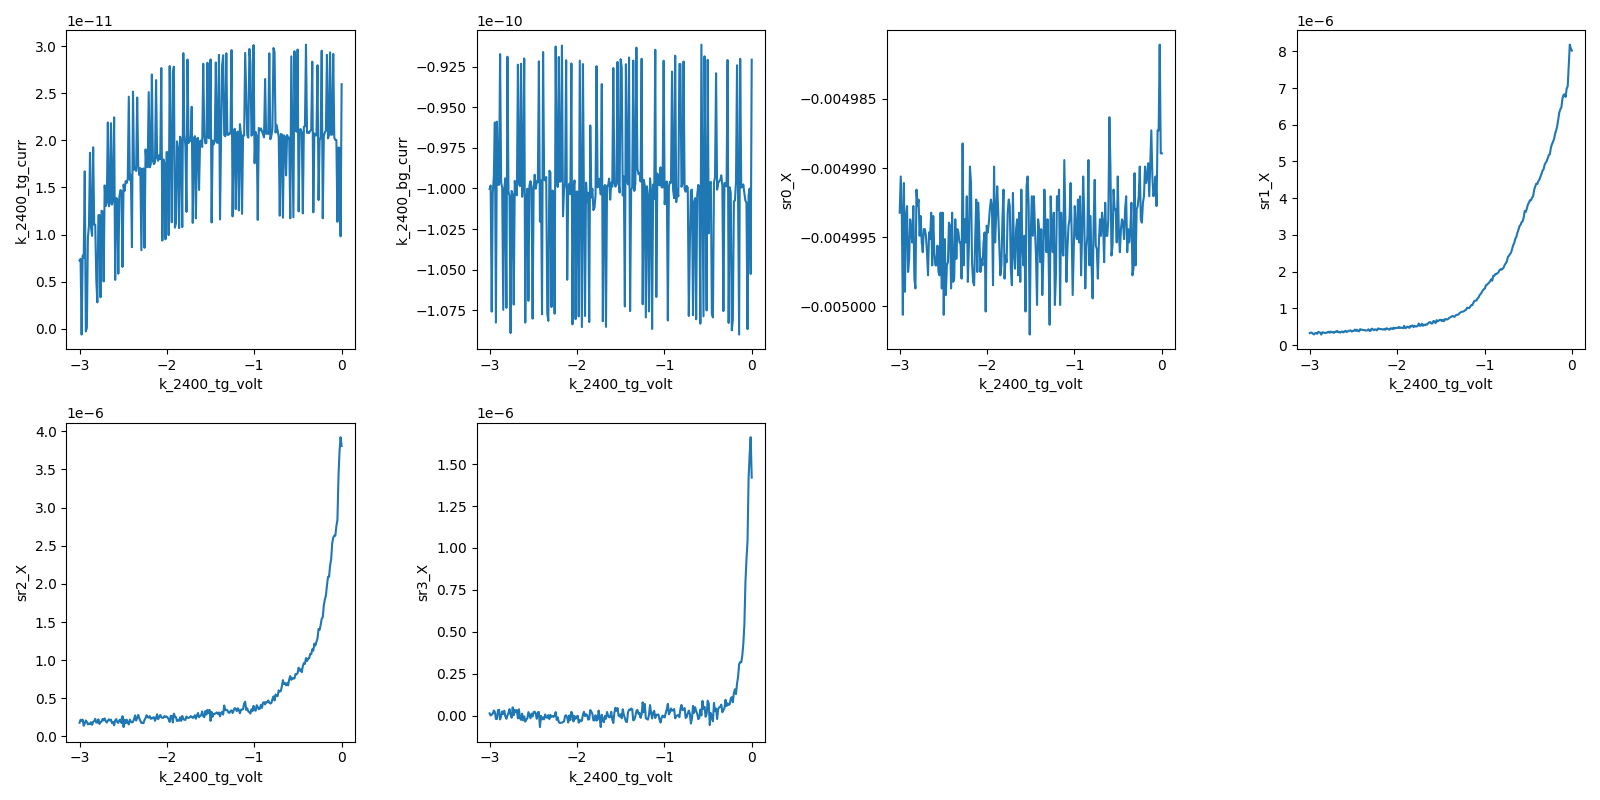

2026-07-14 21:10:46,023 [INFO] Completed in 0h 8m 58s


2026-07-14 21:10:46,023 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\1\data.tsv.gz


2026-07-14 21:10:46,543 [INFO] Ramping k_2400_tg_volt: -3.0 -> 0


2026-07-14 21:10:50,900 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 21:10:51,423 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 21:10:51,441 [INFO] Starting sweep with ID 2


2026-07-14 21:10:51,441 [INFO] Minimum duration 0h 4m 11s


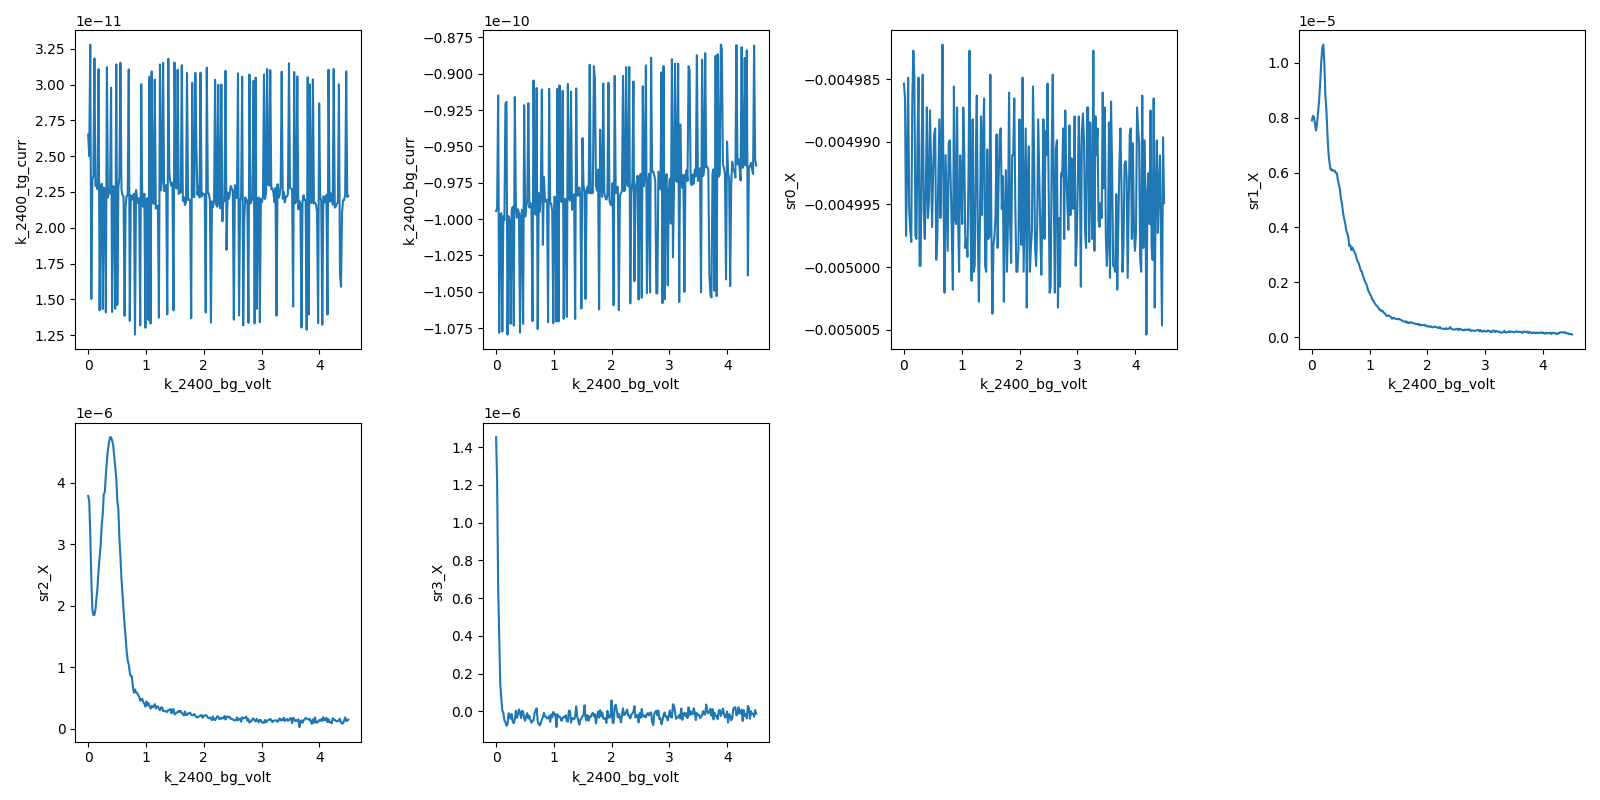

2026-07-14 21:19:46,918 [INFO] Completed in 0h 8m 54s


2026-07-14 21:19:46,919 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\2\data.tsv.gz


2026-07-14 21:19:47,431 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


2026-07-14 21:19:53,587 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 21:19:54,121 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 21:19:54,131 [INFO] Starting sweep with ID 3


2026-07-14 21:19:54,131 [INFO] Minimum duration 0h 4m 11s


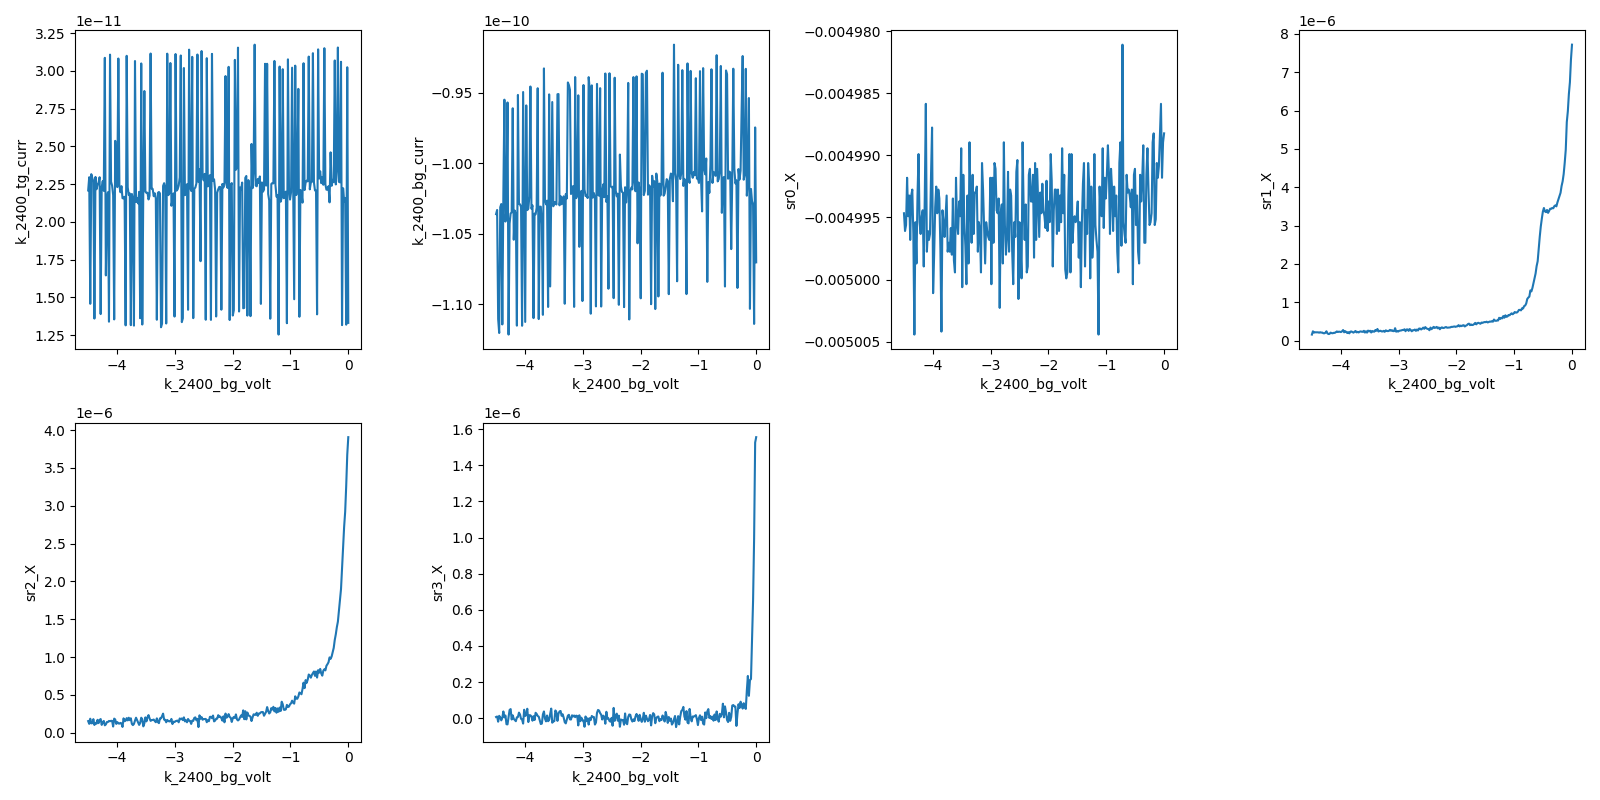

2026-07-14 21:28:48,975 [INFO] Completed in 0h 8m 54s


2026-07-14 21:28:48,976 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\3\data.tsv.gz


2026-07-14 21:28:49,495 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0


all legs done; gates parked at 0


In [17]:
# === Gate C: gate-current sanity check — Cell A (4 legs, one file each) ===
# Preconditions (state this cell assumes but does not set)
_T = T_sample(); _B = magnet.field()
print(f"precheck: T_sample = {_T:.3f} K (expect < 2), B = {_B:+.4f} T (expect ~0), "
      f"Vtg = {k_tg.volt():+.3f}, Vbg = {k_bg.volt():+.3f}, Vsi = {dc205.voltage():+.3f}")
assert _T < 2.0, "not at base T"
assert abs(_B) < 0.05, "magnet not at zero"
assert abs(k_tg.volt()) < 1e-3 and abs(k_bg.volt()) < 1e-3, "gates not parked at 0"

legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),   # +3 / -3 V (SAFETIES limits)
    (k_bg, BG_MAX), (k_bg, BG_MIN),   # +4.5 / -4.5 V
]
n_pts = 251
delay = 1  # s; > 4*tau settling floor (tau = 0.3 s, 24 dB/oct)
lockins = [sr0, sr1, sr2, sr3]

# pA-floor gate-current readback; reset cell restores nplci=1
k_tg.nplci(10)
k_bg.nplci(10)

for gate, v_endpoint in legs:
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}, leg: 0 -> {v_endpoint:+g} V (card limit); '
                  f'other gate 0, Vsi = 0, B = 0, T = {_T:.2f} K, I_bias = 5 nA')

    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(T_sample)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    for lia in lockins:
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)

    try:
        s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)

print("all legs done; gates parked at 0")


### Gate C — Cell B: reset nplci (run only if every leg looked safe)

Undoes Cell A's pA-readback bump and prints the live validators. If any leg leaked, skip this and we stop-and-report instead.


In [18]:
# === Gate C — Cell B: reset gate-current nplci ===
k_tg.nplci(1)
k_bg.nplci(1)
print("k_tg.volt validator:", k_2400_tg.volt.vals)
print("k_bg.volt validator:", k_2400_bg.volt.vals)


k_tg.volt validator: <Numbers -3.0<=v<=3.0>
k_bg.volt validator: <Numbers -4.5<=v<=4.5>


## HERA — E1 engaged (grant: "go for autonomy", recorded in session_notes.md)

First autonomous execute is this read-only kernel-binding probe (brief VERIFY, last item): it must show the instrument-carrying namespace (magnet, Keithleys, DC205, lock-ins) and sane live reads. On green I proceed to Gate C — executing the liveness legs (cell 31) myself.


In [16]:
# HERA — E1 kernel-binding probe (read-only): confirms nb-collab execute lands
# on the operator's instrument-carrying kernel before any autonomous measure cell.
import qcodes
print("instruments:", sorted(qcodes.Instrument._all_instruments.keys()))
print(f"magnet.field = {magnet.field():+.4f} T | T_sample = {T_sample():.3f} K | "
      f"Vtg = {k_tg.volt():+.3f} V | Vbg = {k_bg.volt():+.3f} V | Vsi = {dc205.voltage():+.3f} V")
print("sweep basedir:", sweep.get_basedir() if hasattr(sweep, "get_basedir") else main_dir)
print("binding OK")


instruments: ['dc205', 'k_2400_bg', 'k_2400_tg', 'l335_3', 'magnet', 'sr0', 'sr1', 'sr2', 'sr3']
magnet.field = +0.0033 T | T_sample = 1.150 K | Vtg = +0.000 V | Vbg = +0.000 V | Vsi = +0.000 V
sweep basedir: C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426
binding OK


## HERA — Step 1: 0 T gate map (`gatemap`) for CNP line + (n, D) calibration

Gate C passed (runs 0–3, verdict in ana). Next per the governing investigation (`trilayer-stacking-fs-count` Step 1): the 0 T TG–BG map that `cnp-and-dline-calibration` consumes — CNP ridge per channel → capacitance ratio from the slope → the (n, D) conversion, plus the region survey (clean hole/electron sides, D = 0 line, contact arms staying metallic).

**Design.** TG fast −3 → +3 V, **121 pts (50 mV step)** — Gate C shows the CNP peak ~0.5 V wide, so ≥10 pts across it; BG slow −3 → +3 V, **61 rows (0.1 V step)**. BG is clipped at ±3 V (not the ±4.5 card limit) because the geometry-prior slope (−c_bg/c_tg ≈ −1.3) walks the ridge out of the TG window at |Vbg| ≈ 2.7 V — rows beyond that carry no ridge and little else; the price of full BG coverage would be ~+1.2 h for edge-clipped rows. D = 0 reach on this map: |n| up to ~6×10¹² cm⁻² (geometry prior).

**Sensitivities**: sr1–sr3 stay at 2e-5 (card CNP scale; rails above ~4 kΩ — a railed ridge row is expected at larger |D| and the calibration fit handles it via outlier rejection). sr0 bumped 5 mV → **10 mV** for headroom (it sits at 99.7 % of range at full 5 nA; the card's metallic-regime setting).

**Cost** (calibrated on runs 0–3: 2.13 s/pt at delay = 1 → ~2.4 s/pt at fast_delay = 1.2): 61 × 121 = 7 381 pts ≈ 4.9 h + ~15 min row turnaround → **~5–5.5 h** (overnight run; done ≈ 03:00). Checkpoints: first 3 rows (~15 min in — leakage, railing, dead channel), then mid-run.

Preconditions asserted in-cell: T < 2 K, |B| < 0.05 T, Si at 0 V, gates at 0. Gates park at 0 on completion.


precheck: T=1.151 K (<2), B=+0.0033 T (~0), Vtg=+0.000, Vbg=+0.000, Vsi=+0.000 (all ~0)
2026-07-14 21:34:11,684 [INFO] Ramping k_2400_tg_volt: 0.0 -> -3.0


2026-07-14 21:34:15,564 [INFO] Ramping k_2400_bg_volt: 0.0 -> -3.0


2026-07-14 21:34:19,391 [INFO] Starting megasweep with ID 4


2026-07-14 21:34:19,391 [INFO] Minimum duration 2h 30m 40s


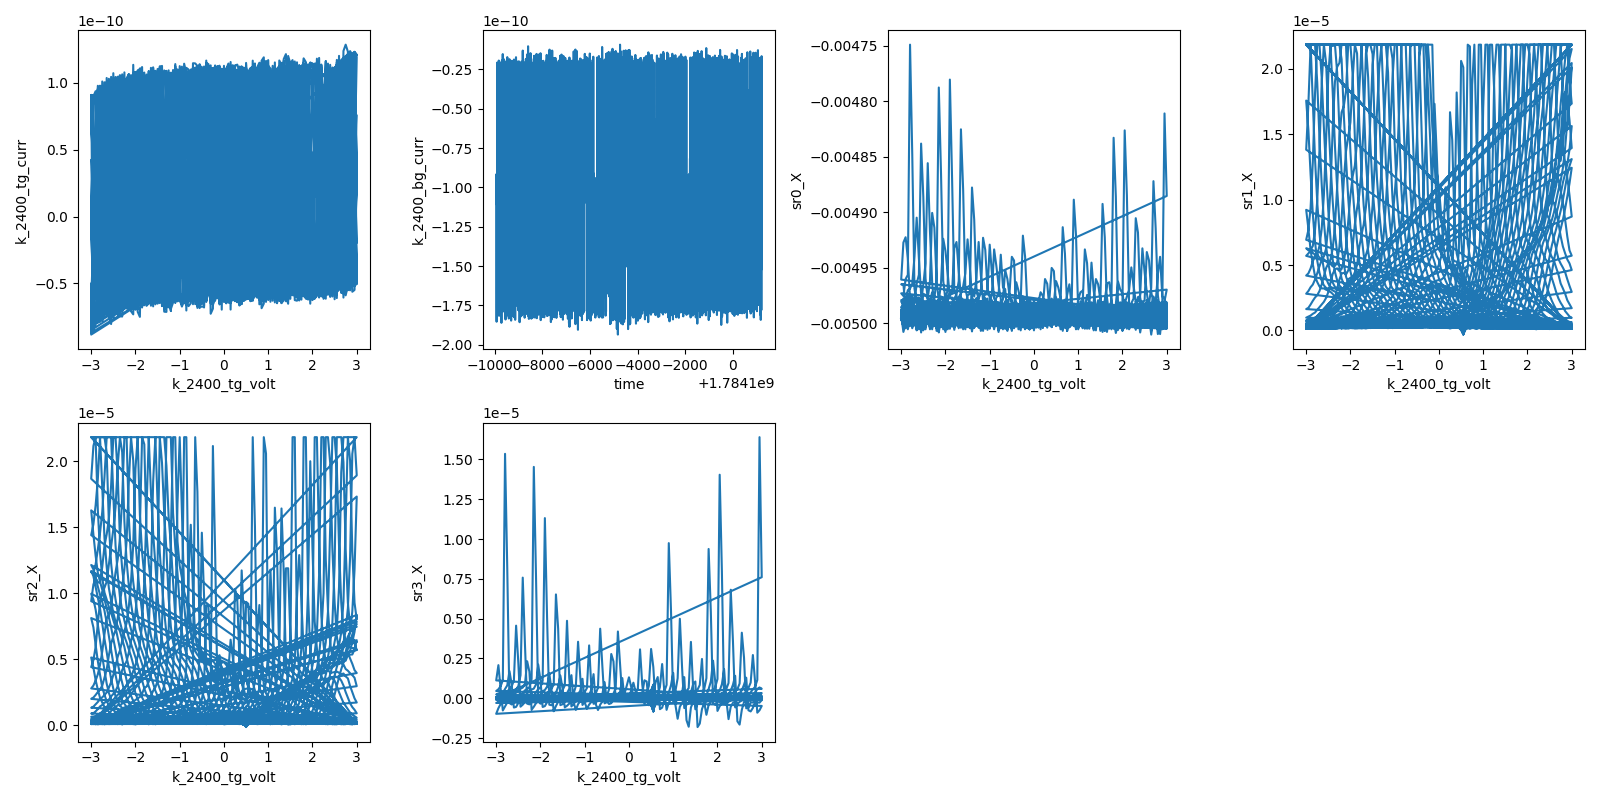

2026-07-15 00:40:06,916 [INFO] Completed in 3h 5m 46s


2026-07-15 00:40:06,917 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\4\data.tsv.gz


2026-07-15 00:40:06,987 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-15 00:40:10,820 [INFO] Ramping k_2400_bg_volt: 3.0 -> 0


gatemap done; gates parked at 0


In [19]:
# === Step 1: 0 T gate map — TG fast (121 pts, -3..+3), BG slow (61 rows, -3..+3) ===
_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.4f} T (~0), Vtg={k_tg.volt():+.3f}, "
      f"Vbg={k_bg.volt():+.3f}, Vsi={dc205.voltage():+.3f} (all ~0)")
assert _T < 2.0 and abs(_B) < 0.05
assert abs(k_tg.volt()) < 1e-3 and abs(k_bg.volt()) < 1e-3 and abs(dc205.voltage()) < 1e-3

# sr0 headroom: 5 nA x 1 MOhm = 5 mV sits at 99.7% of the 5 mV range -> 10 mV
sr0.sensitivity(10e-3)

vtg_fast = np.linspace(-3.0, 3.0, 121)   # 50 mV step, inside validators
vbg_slow = np.linspace(-3.0, 3.0, 61)    # 0.1 V step, ridge in-window to |Vbg|~2.7

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment(f'TG fast -3..+3 (121 pts), BG slow -3..+3 (61 rows), Vsi=0, B=0, '
              f'T={_T:.2f} K, I_bias=5 nA, sens sr1-3 2e-5 / sr0 1e-2, fast_delay=1.2 (4 tau)')

s.ramp(k_tg.volt, vtg_fast[0])
s.ramp(k_bg.volt, vbg_slow[0])

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot(k_tg.volt, k_tg.curr)      # live leakage, swept gate
s.plot('time', k_bg.curr)         # live leakage, stepped gate
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)

try:
    s.megasweep(k_bg.volt, vbg_slow, k_tg.volt, vtg_fast,
                slow_delay=3, fast_delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print("gatemap done; gates parked at 0")


## HERA — Step 3: SdH spot checks (`sdh-spot-check`), hole then electron, n = ∓6×10¹² at D = 0

Calibration is live (run 4; c_bg/c_tg = 1.2774, n_offset = −0.036e12). Per the investigation: two fixed-(n, D = 0) field sweeps **uniform in 1/B**, one per density sign at high |n| — they pin the onset, the tone set vs F_L, the side with cleaner SdH, and the Δ(1/B)/settling the fan inherits.

**Design.** F_L(6×10¹²) = (h/4e)·n = **62 T** (the fastest credible tone). Δ(1/B) = 1/(3·F_L) = 5.4×10⁻³ T⁻¹ (Nyquist ×1.5 margin). Window **[0.25, 8] T** (B_lo below any plausible onset at T_e ≈ 8 K; B_hi = session cap — ~120 periods of F_L in the span). N = 721 points. **Sequencing to never re-traverse**: hole side sweeps 0.25 → 8 T up; electron side runs at 8 T after a gate flip and sweeps 8 → 0.25 T down, parking the magnet low for the fan (which starts at the measured onset).

**Excitation/sensitivity** (deviation from card's zero-field metallic values, stated): I_bias = 20 nA (2 V drive, card's high-|n| setting). The card's sr1 2e-6 would ceiling at 100 Ω — guaranteed clipping under MR at 8 T. Sized instead for the worst corner: sr1/sr2 **2e-5** (1 kΩ ceiling ≈ 20× zero-field R at n = 6e12), sr3 **5e-5** (R_xy(8 T, 6e12) = B/ne ≈ 832 Ω → 16.6 µV, 3× headroom), sr0 **5e-2** (20 mV signal). Signal at B = 0: ~1 µV = 5 % of range — coarse but rising with MR exactly where the FFT reads; the spot check is itself the MR calibrator for the fan's final sizing.

**Cost each**: 7.75 T traverse ≈ 57 min (0.137 T/min floor) + 721 × ~2.3 s ≈ 28 min → **~1.5 h/side** (upper 1.7 h; per-point from runs 0–4). Checkpoints: first rows (~5 min in), then the FFT read between sides — the electron cell only runs after the hole-side verdict.

Preconditions per cell: T < 2 K; hole cell expects B ≈ 0 (magnet parked after run 4), electron cell expects B ≈ 8 T (where the hole sweep ends). Tags: `sdh-spot-check`.


precheck: T=1.154 K (<2), B=+0.003 T (expect ~0), Vsi=+0.000 (0)
target (-6.0e12, D=0) -> Vtg -2.806 V, Vbg -2.196 V (validators fence)
2026-07-15 00:47:00,407 [INFO] Ramping k_2400_tg_volt: 0.0 -> -2.8057145583071


2026-07-15 00:47:04,048 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.196354272644706


2026-07-15 00:47:06,841 [INFO] Ramping magnet_field: 0.003296438356164383 -> 0.25


2026-07-15 00:48:59,404 [INFO] Starting sweep with ID 5


2026-07-15 00:48:59,405 [INFO] Minimum duration 0h 14m 25s


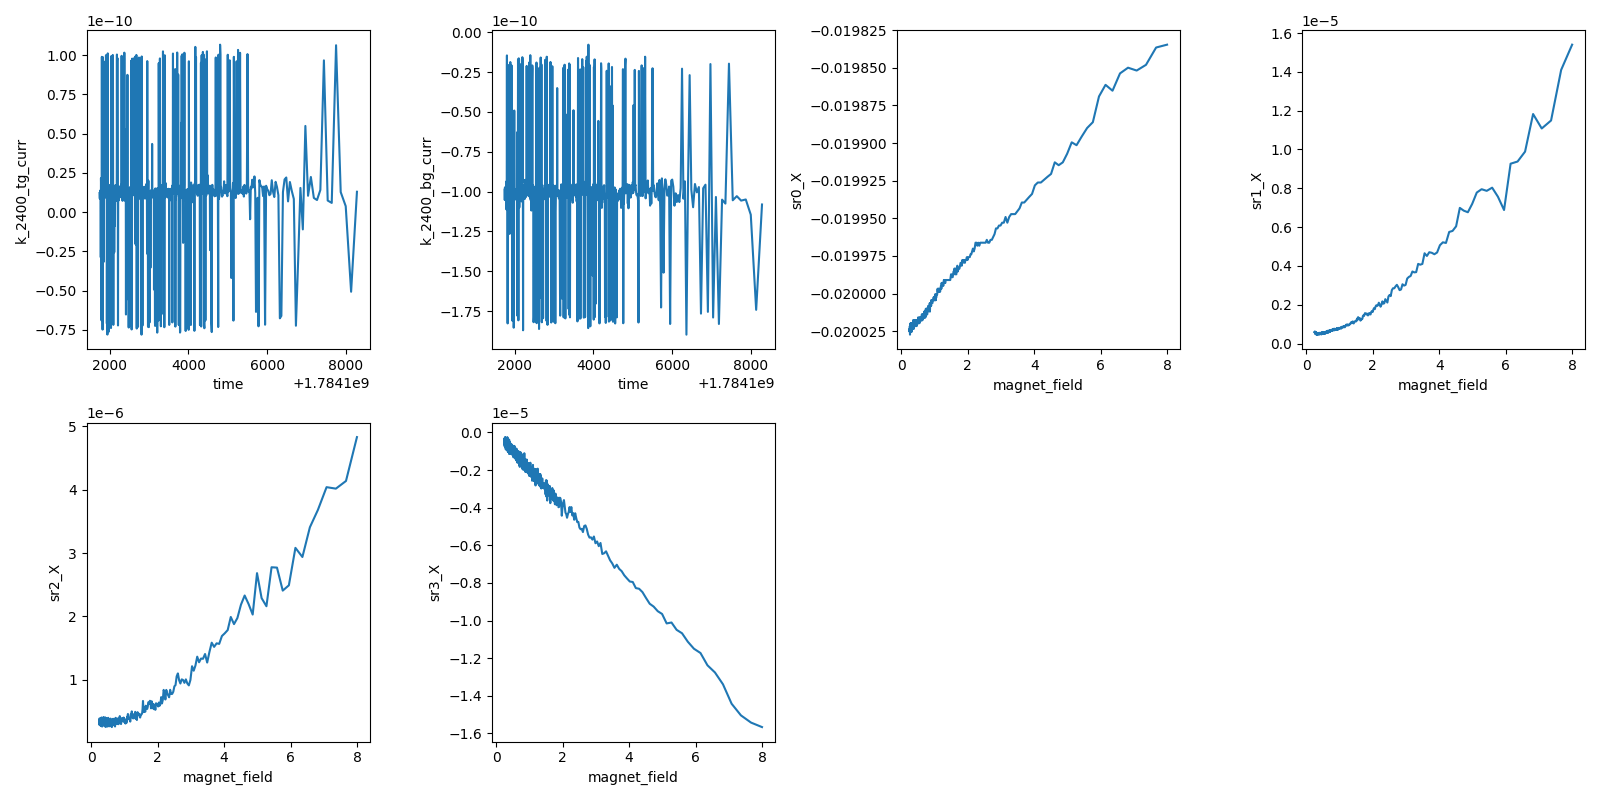

2026-07-15 02:38:03,858 [INFO] Completed in 1h 49m 3s


2026-07-15 02:38:03,859 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\5\data.tsv.gz


hole-side spot check done; magnet at 8 T, gates still at hole point


In [20]:
# === SdH spot check 1/2: HOLE side, n = -6e12 cm^-2, D = 0, B 0.25 -> 8 T (uniform 1/B) ===
from sharpelab_nb.gates import calc_gate_voltages
from hera.analysis import field_invB

_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.3f} T (expect ~0), Vsi={dc205.voltage():+.3f} (0)")
assert _T < 2.0 and abs(_B) < 0.3 and abs(dc205.voltage()) < 1e-3

# session calibration (run 4): ratio data-calibrated, scale geometry-anchored
C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365   # F/m^2, F/m^2, 1e12 cm^-2
n_target, D_target = -6.0, 0.0
vtg_t, vbg_t = calc_gate_voltages(n_target, D_target, C_TG, C_BG, n_offset=N_OFF)
print(f"target ({n_target:+.1f}e12, D=0) -> Vtg {vtg_t:+.3f} V, Vbg {vbg_t:+.3f} V (validators fence)")

# high-|n| metallic excitation; sens sized for 8 T worst corner (see markdown)
sr1.amplitude(2.0)          # I_bias = 20 nA through 100 MOhm
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)

B_vec = field_invB(0.25, 8.0, 721)   # d(1/B) = 5.4e-3 = 1/(3*F_L(6e12))

s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'hole side: n = {n_target}e12 cm^-2, D = 0 -> (Vtg, Vbg) = ({vtg_t:.3f}, {vbg_t:.3f}); '
              f'B 0.25->8 T uniform 1/B, N=721, d(1/B)=5.4e-3 (Nyquist x3 on F_L=62 T); '
              f'I_bias=20 nA, sens sr1/sr2 2e-5 sr3 5e-5, T={_T:.2f} K, cal run 4')

s.ramp(k_tg.volt, vtg_t)
s.ramp(k_bg.volt, vbg_t)
s.ramp(magnet.field, B_vec[0])       # blocking ramp; the set call is the settle

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

s.sweep(magnet.field, B_vec, delay=1.2)
print("hole-side spot check done; magnet at 8 T, gates still at hole point")


### Spot check 2/2: ELECTRON side — runs only after the hole-side FFT verdict

Gate flip at 8 T (crosses the CNP at high field — transiently high-R, harmless within validators), then sweep down 8 → 0.25 T on the same 1/B grid, parking the magnet low for the fan. Same excitation/sensitivities unless the hole-side checkpoint said adjust (any change will be noted in a fresh comment before execution).


precheck: T=1.264 K (<2), B=+8.003 T (expect ~8), Vsi=+0.000 (0)
target (+6.0e12, D=0) -> Vtg +2.840 V, Vbg +2.223 V
2026-07-15 02:41:39,106 [INFO] Ramping k_2400_tg_volt: -2.8055 -> 2.8400596849536033


2026-07-15 02:41:46,316 [INFO] Ramping k_2400_bg_volt: -2.1965 -> 2.223240138646729


2026-07-15 02:42:01,923 [INFO] Starting sweep with ID 6


2026-07-15 02:42:01,924 [INFO] Minimum duration 0h 14m 25s


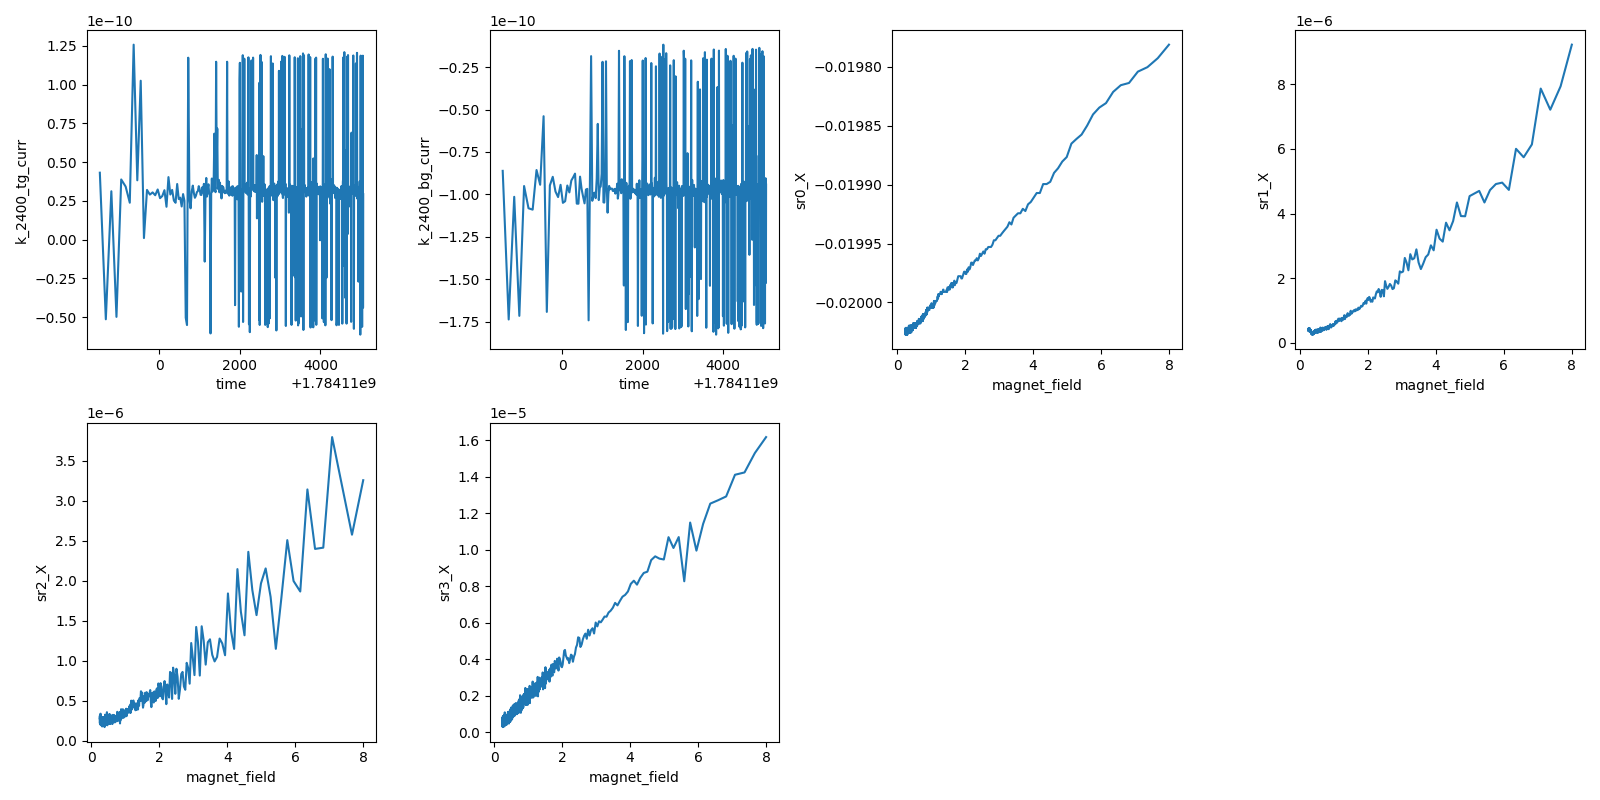

2026-07-15 04:31:04,969 [INFO] Completed in 1h 49m 2s


2026-07-15 04:31:04,970 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\6\data.tsv.gz


electron-side spot check done; magnet at 0.25 T; parking gates at 0


In [21]:
# === SdH spot check 2/2: ELECTRON side, n = +6e12 cm^-2, D = 0, B 8 -> 0.25 T (uniform 1/B) ===
from sharpelab_nb.gates import calc_gate_voltages
from hera.analysis import field_invB

_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.3f} T (expect ~8), Vsi={dc205.voltage():+.3f} (0)")
assert _T < 2.0 and _B > 7.5 and abs(dc205.voltage()) < 1e-3

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
n_target, D_target = +6.0, 0.0
vtg_t, vbg_t = calc_gate_voltages(n_target, D_target, C_TG, C_BG, n_offset=N_OFF)
print(f"target ({n_target:+.1f}e12, D=0) -> Vtg {vtg_t:+.3f} V, Vbg {vbg_t:+.3f} V")

B_vec = field_invB(8.0, 0.25, 721)

s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'electron side: n = +{n_target}e12 cm^-2, D = 0 -> (Vtg, Vbg) = ({vtg_t:.3f}, {vbg_t:.3f}); '
              f'B 8->0.25 T uniform 1/B, N=721, d(1/B)=5.4e-3; I_bias=20 nA, '
              f'sens sr1/sr2 2e-5 sr3 5e-5, T={_T:.2f} K, cal run 4')

s.ramp(k_tg.volt, vtg_t)
s.ramp(k_bg.volt, vbg_t)
interruptible_sleep(10)              # settle after crossing CNP at 8 T

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

s.sweep(magnet.field, B_vec, delay=1.2)
print("electron-side spot check done; magnet at 0.25 T; parking gates at 0")
k_tg.volt(0); k_bg.volt(0)


## HERA — Step 4: D = 0 Landau fan, electron side (`landau-fan-vti`)

Spot checks done (runs 5/6, analysis in ana). **Side choice: electron** — computed onset 1.33 T vs 3.5 T (hole), i.e. twice the 1/B record → δF ≈ 1.6 T per column, which is what the 53 / 67 / 14 T tone separation needs. The fan's job: per-column peak sets vs the Hall-pinned F_L(n), the Luttinger partition f_B(n) + f_s(n) = F_L(n), tone n-tracking (Onsager), and the QH corner for the lever-arm upgrade.

**Design (floored):**
- **Fast axis**: paired n-line at D = 0, n = +2.0 → +6.3×10¹² cm⁻², **51 columns** (δn = 0.086e12; ray-Nyquist ≥2/spacing holds for B ≥ 2.5 T — Středa/ray reads below 2.5 T are out of scope, FFT reads unaffected). Gate vectors from the run-4 calibration; all inside validators.
- **Slow axis**: `field_invB(1.33, 8.0, 126)` — B_lo = the **computed** run-6 onset; Δ(1/B) = 5.0×10⁻³ → unaliased to 100 T: all claim tones (≤ 68 T) at ≥ 1.5× Nyquist; the 2f_B ≈ 104 T harmonic aliases to ~96 T, inside a quarantined 90–100 T band stated per column (checked at n_max = 6.3e12 — not inherited).
- **Sensitivity resize for the worst corner** (low-n × high-B, QH regime ν ≈ 10): sr1/sr2 1e-4 (5 kΩ ceiling vs ~3 kΩ expected LL peaks at n = 2e12, 8 T), sr3 2e-4 (10 kΩ vs R_xy ≈ 2.5 kΩ), sr0 5e-2. Trade: start-corner signal (60 Ω at 6.3e12, 1.33 T) reads at ~1 % of range — grainy in the onset rows, clean where the claims live.
- **Coverage trade stated**: hole side not fanned (weaker window, δF 6.5 T — spot check run 5 is its record); Onsager-overlay claims floored at |n| ≤ 3.5e12 (model validity clamp); n > 3.5e12 carries the algebraic partition + tone-resolution claims and the run-5/6 spot-check cross-check at 6.4e12.

**Cost** (per-point 2.3 s measured, runs 4–6): 126 rows × (51 × 2.3 s + ~15 s turnaround) ≈ 4.6 h + 6.7 T traverse ≈ 49 min + positioning ≈ **5.5–6.5 h** (done ≈ 13:00–14:00). Checkpoints: first 3 rows (~15 min), then interim per-column FFT at ~½ (B ≈ 2.5 T… uniform-1/B front-loads rows), then completion. Ends at 8 T, gates parked at 0.

Preconditions: T < 2 K, magnet at ~0.25 T (parked by run 6), Si = 0. Tag: `landau-fan-vti`.


precheck: T=1.165 K (<2), B=+0.253 T (expect ~0.25), Vsi=+0.000 (0), Vtg=+0.000, Vbg=+0.000 (parked 0)
n-line: Vtg +0.958..+2.981, Vbg +0.750..+2.334
2026-07-15 04:36:12,241 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0.9581349372000352


2026-07-15 04:36:13,500 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0.7500420015495838


2026-07-15 04:36:14,437 [INFO] Ramping magnet_field: 0.25329143835616436 -> 1.33


2026-07-15 04:44:09,455 [INFO] Starting multimegasweep with ID 7


2026-07-15 04:44:09,456 [INFO] Minimum duration 2h 14m 49s


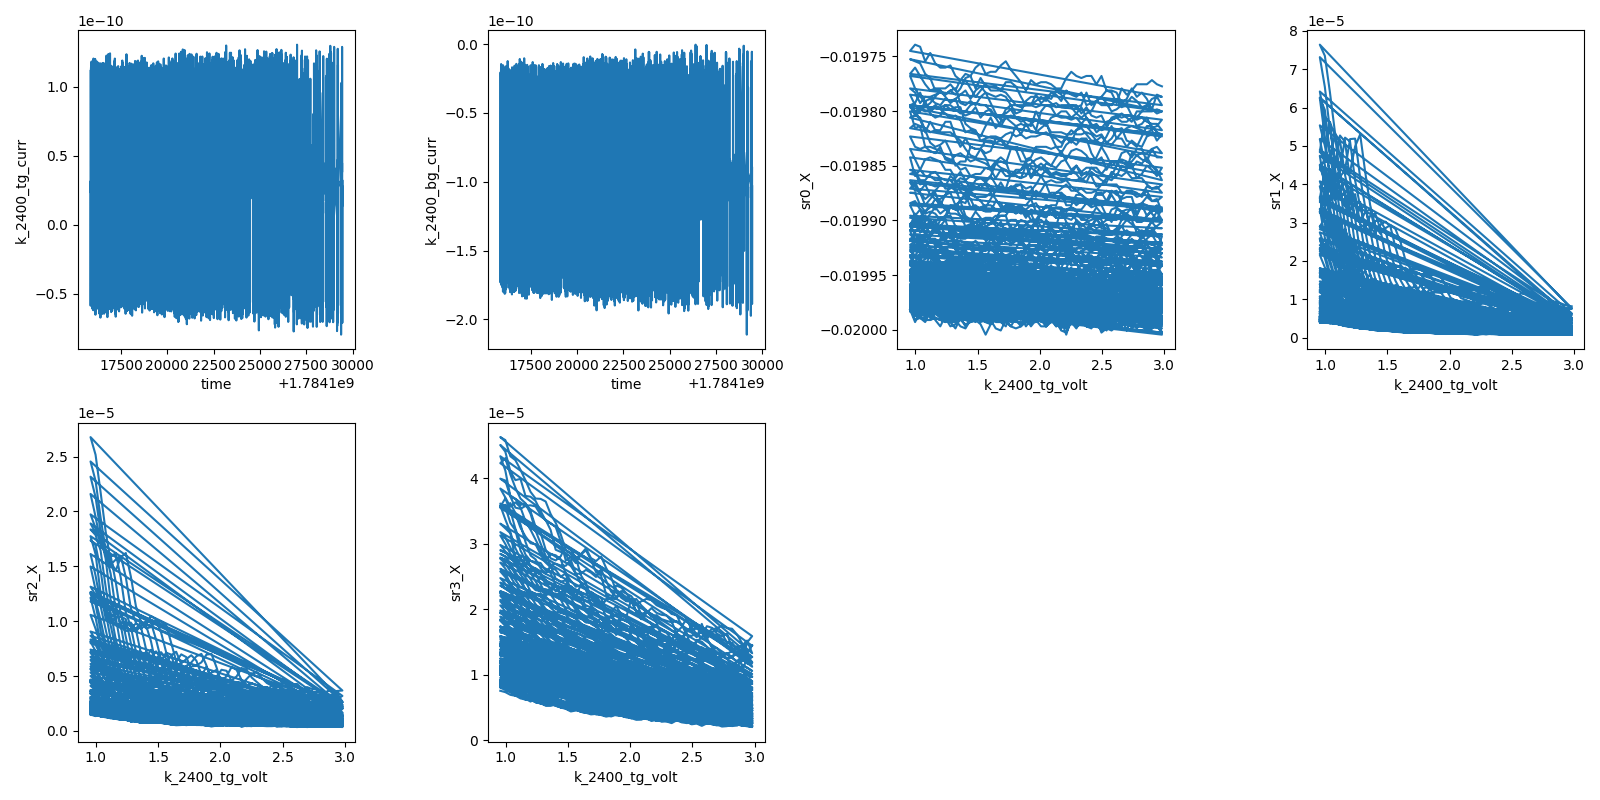

2026-07-15 08:30:47,541 [INFO] Completed in 3h 46m 37s


2026-07-15 08:30:47,541 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\7\data.tsv.gz


2026-07-15 08:30:47,612 [INFO] Ramping k_2400_tg_volt: 2.981 -> 0


2026-07-15 08:30:51,417 [INFO] Ramping k_2400_bg_volt: 2.3335 -> 0


fan done; magnet at 8 T, gates parked at 0


In [22]:
# === Step 4: D=0 Landau fan, electron side — B slow (126 rows, 1.33->8 T uniform 1/B),
# === n fast (51 cols, +2.0 -> +6.3 e12) ===
from sharpelab_nb.gates import calc_gate_voltages
from hera.analysis import field_invB

_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.3f} T (expect ~0.25), Vsi={dc205.voltage():+.3f} (0), "
      f"Vtg={k_tg.volt():+.3f}, Vbg={k_bg.volt():+.3f} (parked 0)")
assert _T < 2.0 and abs(_B) < 0.6 and abs(dc205.voltage()) < 1e-3

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365   # run-4 calibration
ns = np.linspace(2.0, 6.3, 51)                      # 1e12 cm^-2, electron side
Vtgs, Vbgs = calc_gate_voltages(ns, np.zeros_like(ns), C_TG, C_BG, n_offset=N_OFF)
assert np.abs(Vtgs).max() <= 3.0 and np.abs(Vbgs).max() <= 4.5
print(f"n-line: Vtg {Vtgs[0]:+.3f}..{Vtgs[-1]:+.3f}, Vbg {Vbgs[0]:+.3f}..{Vbgs[-1]:+.3f}")

B_vec = field_invB(1.33, 8.0, 126)                  # d(1/B) = 5.0e-3; B_lo = computed onset (run 6)

# worst-corner sensitivity sizing (n=2e12 @ 8 T, QH regime)
sr1.sensitivity(1e-4); sr2.sensitivity(1e-4); sr3.sensitivity(2e-4); sr0.sensitivity(5e-2)

s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment(f'D = 0, n = +2.0 to +6.3 e12 (51 cols), B = 1.33 to 8 T uniform 1/B '
              f'(126 rows, d(1/B)=5.0e-3, B_lo = run-6 computed onset); I_bias=20 nA, '
              f'sens sr1/sr2 1e-4 sr3 2e-4, fast_delay=1.2 (4 tau), T={_T:.2f} K, cal run 4')

s.ramp(k_tg.volt, Vtgs[0])
s.ramp(k_bg.volt, Vbgs[0])
s.ramp(magnet.field, B_vec[0])       # blocking ramp = the settle (VTI variant step 4)

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)

try:
    s.multimegasweep([magnet.field], [B_vec], [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=3, fast_delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print("fan done; magnet at 8 T, gates parked at 0")


## HERA — ride-home: hole-side spot check repeat (free measured traverse, 8 → 0.25 T)

The arc is complete (call in ana). The magnet must return from 8 T regardless (~1 h); riding it down as a measured `sdh-spot-check` at the run-5 hole point (n = −6×10¹², D = 0) is free data: co-adding with run 5 improves the hole-side FFT SNR where the ~13 T partner was detrender-sensitive. Same acquisition as run 5 (20 nA; sens back to the spot-check values). Ends at 0.25 T, gates parked at 0 — clean handoff state. Cost: the traverse we owe anyway + ~28 min of dwell.


precheck: T=1.272 K (<2), B=+8.003 T (expect ~8), Vsi=+0.000 (0)
target (-6.0e12, D=0) -> Vtg -2.806, Vbg -2.196
2026-07-15 08:39:26,971 [INFO] Ramping k_2400_tg_volt: 0.0 -> -2.8057145583071


2026-07-15 08:39:30,612 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.196354272644706


2026-07-15 08:39:43,429 [INFO] Starting sweep with ID 8


2026-07-15 08:39:43,430 [INFO] Minimum duration 0h 14m 25s


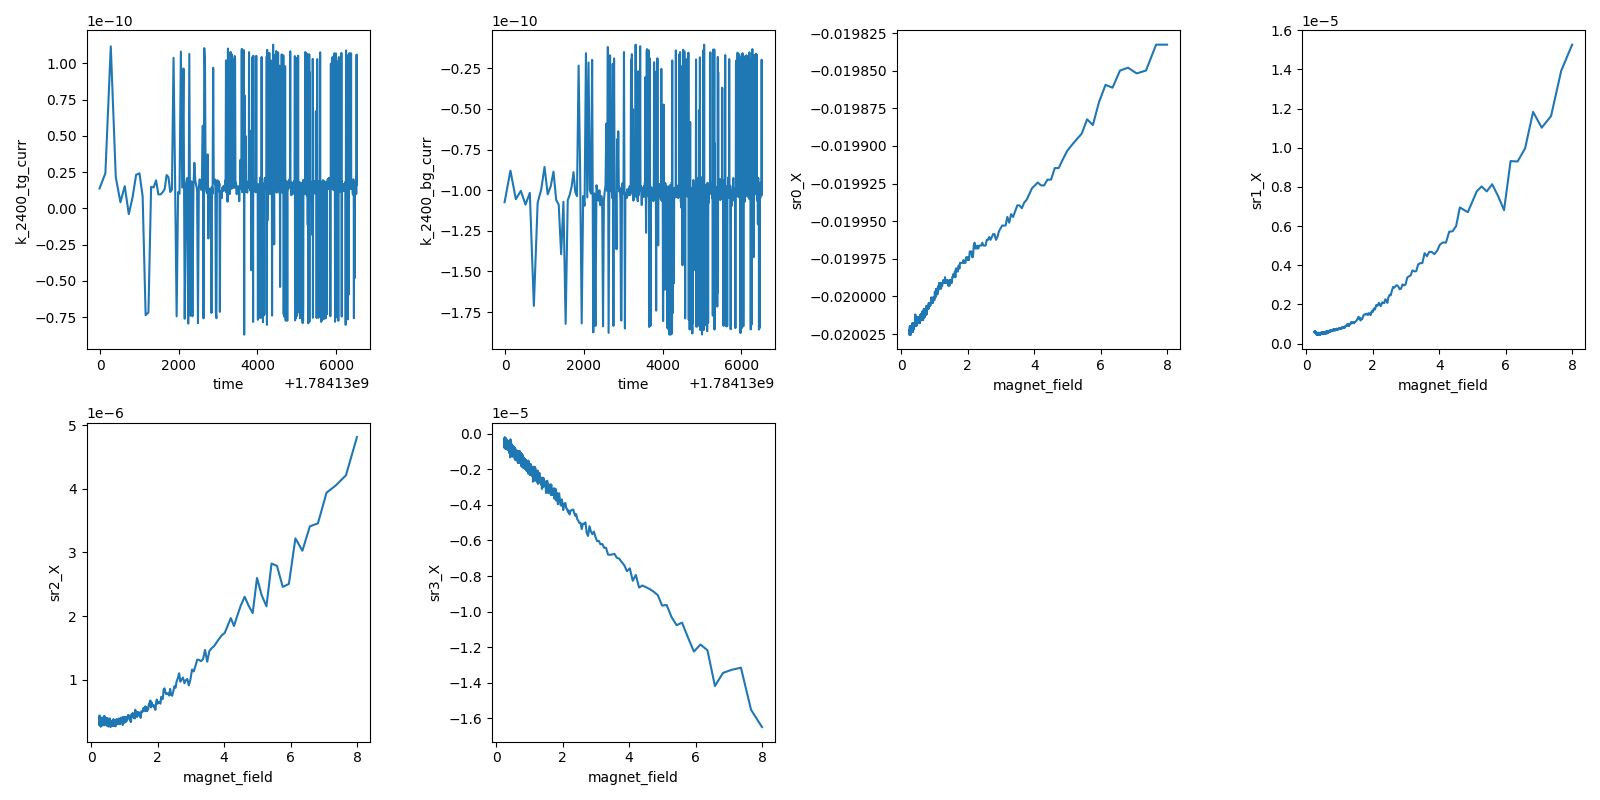

2026-07-15 10:28:47,816 [INFO] Completed in 1h 49m 3s


2026-07-15 10:28:47,817 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\8\data.tsv.gz


ride-home done; magnet at 0.25 T, gates parked at 0


In [23]:
# === Ride-home: hole side n = -6e12, D = 0, B 8 -> 0.25 T (repeat of run 5, reversed) ===
from sharpelab_nb.gates import calc_gate_voltages
from hera.analysis import field_invB

_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.3f} T (expect ~8), Vsi={dc205.voltage():+.3f} (0)")
assert _T < 2.0 and _B > 7.5 and abs(dc205.voltage()) < 1e-3

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(-6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
print(f"target (-6.0e12, D=0) -> Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
B_vec = field_invB(8.0, 0.25, 721)

s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'hole side REPEAT (ride-home w/ run 5): n = -6e12, D = 0 -> ({vtg_t:.3f}, {vbg_t:.3f}); '
              f'B 8->0.25 T uniform 1/B N=721; I_bias=20 nA, sens sr1/sr2 2e-5 sr3 5e-5, '
              f'T={_T:.2f} K, cal run 4')

s.ramp(k_tg.volt, vtg_t)
s.ramp(k_bg.volt, vbg_t)
interruptible_sleep(10)   # settle after crossing CNP at 8 T

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

try:
    s.sweep(magnet.field, B_vec, delay=1.2)
finally:
    k_tg.volt(0); k_bg.volt(0)
print("ride-home done; magnet at 0.25 T, gates parked at 0")


## HERA — park: magnet to 0 T

Session arc complete (call in ana). Final tidy: ramp 0.25 → 0 T (~2 min) so the rig hands off at true zero.

In [24]:
print(f'B before: {magnet.field():+.4f} T')
magnet.field(0.0)
print(f'B parked: {magnet.field():+.4f} T; gates: Vtg={k_tg.volt():+.3f}, Vbg={k_bg.volt():+.3f}, Vsi={dc205.voltage():+.3f}; T={T_sample():.3f} K')

B before: +0.2533 T


B parked: -0.0002 T; gates: Vtg=+0.000, Vbg=+0.000, Vsi=+0.000; T=1.172 K


## HERA — spot-check redesign validation: uniform-B collection, electron point (E0 — operator runs)

Head-to-head against run 6 (same point, n = +6×10¹², D = 0): sweep **uniform in B**, 1.33 → 8 T, **ΔB = 9.5 mT (703 pts)** — chosen so the 1/B Nyquist still holds at the low-B end (ΔB ≤ Δ(1/B)·B_lo², Δ(1/B) = 1/(3·F_L)). High-B sampling goes from ~2.8 to ~100 pts/period; no blind multi-minute ramps between points; the live trace should read like a normal MR sweep. Analysis path unchanged — `sdh_fft` resamples internally; I'll compare FFTs and peak stability against run 6 when it lands.

**Cost**: ~703 × (4.2 s ramp + 2.3 s dwell/read) ≈ 76 min + ~10 min positioning (0 → 1.33 T) → **~1.4–1.5 h**. Ends at 8 T with gates at the electron point — if we want it back down afterwards, say so and I'll stage a ride-home.

Preconditions: magnet at ~0 (parked), T < 2 K, Si 0. Sensitivities re-asserted to spot-check values in-cell. Tag: `sdh-spot-check` (+ uniform-B variant note in the comment).


precheck: T=1.170 K (<2), B=+0.003 T (expect ~0), Vsi=+0.000 (0)
target (+6.0e12, D=0) -> Vtg +2.840, Vbg +2.223
2026-07-15 11:48:25,347 [INFO] Ramping k_2400_tg_volt: 0.0 -> 2.8400596849536033
2026-07-15 11:48:28,981 [INFO] Ramping k_2400_bg_volt: 0.0 -> 2.223240138646729
2026-07-15 11:48:31,763 [INFO] Ramping magnet_field: 0.0032752328767123285 -> 1.33
2026-07-15 11:58:16,298 [INFO] Starting sweep with ID 9
2026-07-15 11:58:16,300 [INFO] Minimum duration 0h 14m 3s


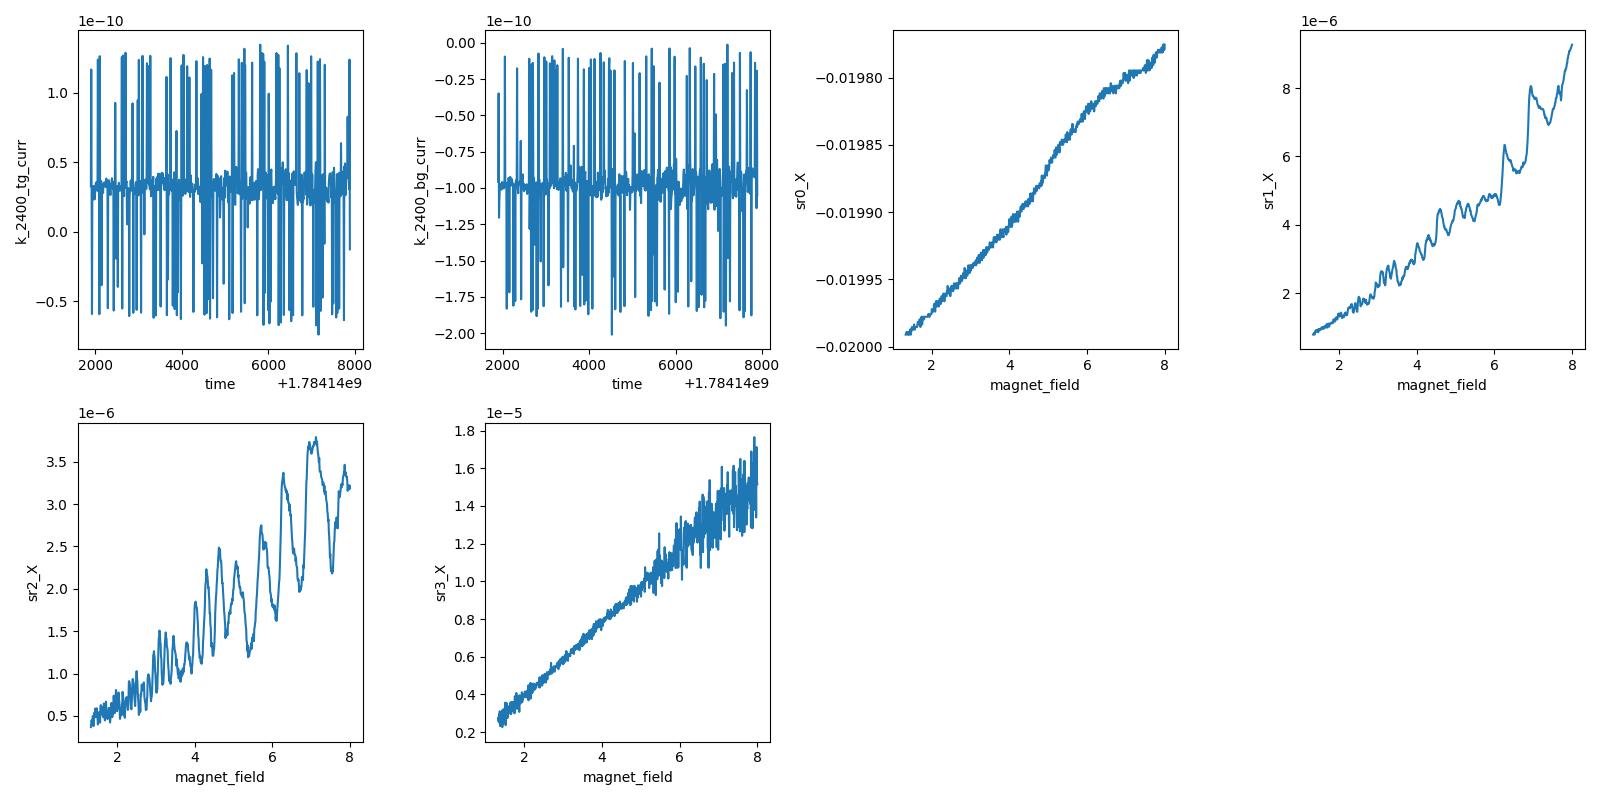

2026-07-15 13:38:11,531 [INFO] Completed in 1h 39m 54s
2026-07-15 13:38:11,532 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\9\data.tsv.gz
uniform-B spot check done; magnet at 8 T, gates at electron point


In [25]:
# === Spot-check redesign validation: uniform-B, electron n = +6e12, D = 0, 1.33 -> 8 T ===
from sharpelab_nb.gates import calc_gate_voltages

_T = T_sample(); _B = magnet.field()
print(f"precheck: T={_T:.3f} K (<2), B={_B:+.3f} T (expect ~0), Vsi={dc205.voltage():+.3f} (0)")
assert _T < 2.0 and abs(_B) < 0.3 and abs(dc205.voltage()) < 1e-3

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
print(f"target (+6.0e12, D=0) -> Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)

B_vec = np.linspace(1.33, 8.0, 703)   # uniform B, dB = 9.5 mT = d(1/B)_Nyq * B_lo^2

s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'UNIFORM-B collection variant (head-to-head vs run 6): electron n = +6e12, '
              f'D = 0 -> ({vtg_t:.3f}, {vbg_t:.3f}); B 1.33->8 T linear, N=703, dB=9.5 mT; '
              f'I_bias=20 nA, sens sr1/sr2 2e-5 sr3 5e-5, T={_T:.2f} K, cal run 4')

s.ramp(k_tg.volt, vtg_t)
s.ramp(k_bg.volt, vbg_t)
s.ramp(magnet.field, B_vec[0])

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)

s.sweep(magnet.field, B_vec, delay=1.2)
print("uniform-B spot check done; magnet at 8 T, gates at electron point")


## HERA — thermal-machinery validation: base → 3 K → 10 K → 50 K → base-ish (E0 — operator runs)

Per operator ruling (session notes): `temperature-dependence` unblocked; `heater.set_both(T, ratio=0.99)` is the sanctioned control call; ranges authorized to 50 K. This cell validates the machinery before the LK ladder: three plateaus covering both heater-range bands — **3 K, 10 K** (range 1) and **50 K** (range 2) — each settle-verified against the worker logfile (never GPIB polling), then `heater.off('both')` and a monitored drift back to **≤ 1.5 K**.

**What it checks per plateau**: settle time (feeds ladder pricing), stability over a 60 s hold (tol = max(50 mK, 0.5 %·T)), and vaporizer tracking (setpoint ratio 0.99 — a lagging/runaway T_vap is the old failure mode and aborts the cell). Gates parked at 0 first; magnet stays at 8 T (envelope: consideration zone needs > 10 T *and* > 15 K — not entered; Cernox field error at 3 K/8 T is tens-of-mK systematic, fine for a machinery check).

**Abort safety**: all waits are `interruptible_sleep`; any exception or interrupt lands in the `finally`, which turns **both heaters off** — the safe state (drift to base).

**Cost (this cell is the calibrator — no prior thermal excursion this session)**: plateaus ~5–10 min each incl. climbs, cooldown 50 → 1.5 K is the unknown (est. 30–60 min on He flow) → **~1.5–2 h total**, generous timeouts throughout. Settle-time summary printed at the end. No run dir (control cell — the record is the cell output; the ladder's runs will carry the data).


In [ ]:
# === Thermal-machinery validation: 3 K / 10 K / 50 K plateaus, then off -> base-ish ===
import os, time
from sharpelab_nb.constants import VTI as _VTI

# park gates for the thermal excursion
k_tg.volt(0); k_bg.volt(0)
print(f"gates parked: Vtg={k_tg.volt():+.3f}, Vbg={k_bg.volt():+.3f}; B={magnet.field():+.3f} T (stays)")

def _logfile_fresh(max_age_s=30):
    paths = [p for p in _VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
    age = time.time() - max(os.path.getmtime(p) for p in paths)
    assert age < max_age_s, f"T_sample logfile stale ({age:.0f} s) — lakeshore worker dead?"
    return age

_logfile_fresh()
print(f"start: T_sample={T_sample():.3f} K, T_vap={T_vaporizer():.3f} K, "
      f"ranges (smp/vap)=({heater.sample_range()},{heater.vaporizer_range()})")

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both + settle-verify off the worker logfile. Returns settle time [s]."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1500)
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges (smp/vap)=({heater.sample_range()},{heater.vaporizer_range()}), tol={tol*1e3:.0f} mK")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        _logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert Tv < target * 1.3 + 2, f"vaporizer overshoot: T_vap={Tv:.2f} K at target {target} K"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (held {hold_s} s within {tol*1e3:.0f} mK; T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

summary = {}
try:
    for target in (3.0, 10.0, 50.0):
        summary[target] = set_T_verified(target)
finally:
    heater.off('both')
    print("heaters OFF (both) — drifting to base")

# monitored cooldown to <= 1.5 K
t0 = time.time()
while True:
    interruptible_sleep(30)
    _logfile_fresh()
    el, T = time.time() - t0, T_sample()
    if int(el) % 300 < 30:
        print(f"    cooldown {el/60:4.1f} min  T={T:.3f} K")
    if T <= 1.5:
        summary["cooldown_50K_to_1.5K"] = el
        print(f"    BASE-ISH reached: {T:.3f} K in {el/60:.1f} min")
        break
    if el > 5400:
        raise RuntimeError(f"cooldown timeout: T={T:.3f} K after 90 min")

print("\n=== machinery validation summary ===")
for k, v in summary.items():
    print(f"  {k}: {v:.0f} s ({v/60:.1f} min)")
print(f"end state: T={T_sample():.3f} K, T_vap={T_vaporizer():.3f} K, heaters off, gates 0, B={magnet.field():+.3f} T")


## HERA — REVISED plan (supersedes the previous cell, which should NOT be run — its cooldown phase is replaced by the LK ladder)

**Cell A (this one): prove the machinery up — base → 3 K → 10 K → 50 K, ending HOLDING at 50 K.**
Same validation as before (both range bands, logfile-freshness guard per poll, vaporizer-runaway assert, interruptible, heaters-off on any exception via `finally` — but on *success* it holds at 50 K and hands off to the ladder cell). Gates parked, B stays at 8 T. ~45–55 min.

**Cell B (next): LK-mass ladder DOWN — 8 rungs, 25 → 1.5 K, one field sweep per rung.**
Runs only after A's plateau numbers look right.


In [26]:
# === Cell A: thermal proof base -> 3 -> 10 -> 50 K, END HOLDING AT 50 K ===
import os, time
from sharpelab_nb.constants import VTI as _VTI

k_tg.volt(0); k_bg.volt(0)
print(f"gates parked; B={magnet.field():+.3f} T (stays)")

def logfile_fresh(max_age_s=30):
    paths = [p for p in _VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
    age = time.time() - max(os.path.getmtime(p) for p in paths)
    assert age < max_age_s, f"T_sample logfile stale ({age:.0f} s) — lakeshore worker dead?"

logfile_fresh()
print(f"start: T={T_sample():.3f} K, T_vap={T_vaporizer():.3f} K")

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both(target, 0.99) + settle-verify off the worker logfile. Returns settle time [s]."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1800)
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges=({heater.sample_range()},{heater.vaporizer_range()}), tol={tol*1e3:.0f} mK")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert Tv < target * 1.3 + 2, f"vaporizer overshoot: T_vap={Tv:.2f} K"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

settle_log = {}
try:
    for target in (3.0, 10.0, 50.0):
        settle_log[target] = set_T_verified(target)
except BaseException:
    heater.off('both')
    print("EXCEPTION/interrupt -> heaters OFF (safe drift)")
    raise

print("\n=== up-leg summary (feeds ladder pricing) ===")
for k, v in settle_log.items():
    print(f"  {k} K: settled in {v:.0f} s ({v/60:.1f} min)")
print(f"HOLDING at 50 K (heaters ON). T={T_sample():.3f} K. Run the ladder cell next.")


gates parked; B=+8.003 T (stays)
start: T=1.273 K, T_vap=1.057 K
--> set_both(3.0, 0.99): ranges=(1,1), tol=50 mK


       60 s  T=  2.898  T_vap=  1.964


       70 s  T=  2.898  T_vap=  1.964


      120 s  T=  2.918  T_vap=  1.981


      180 s  T=  2.960  T_vap=  1.993


...

      180 s  T= 10.025  T_vap=  9.897


    SETTLED 10.0 K in 220 s (T_vap=9.903)
--> set_both(50.0, 0.99): ranges=(2,2), tol=250 mK


       70 s  T= 43.317  T_vap= 40.435


      130 s  T= 50.021  T_vap= 49.536


    SETTLED 50.0 K in 150 s (T_vap=49.524)

=== up-leg summary (feeds ladder pricing) ===
  3.0 K: settled in 240 s (4.0 min)
  10.0 K: settled in 220 s (3.7 min)
  50.0 K: settled in 150 s (2.5 min)
HOLDING at 50 K (heaters ON). T=50.012 K. Run the ladder cell next.


### Cell B — LK-mass ladder, 25 → 1.5 K on the cooldown (`temperature-dependence` Flavor B; unblocked by operator ruling, see session notes)

**Goal**: per-branch effective masses of f_s (~10–14 T), f_B (~53 T), f_top (~67 T) at the electron point (n = +6×10¹², D = 0) — the decider for the f_top fork: two distinct masses (light ML + heavy BL) confirm the pair; an f_top mass ≥ m_B + m_s says breakdown/intermod, a distinct third mass says third band (ABC domain). Plus the beat exclusion: a coexisting component *lighter* than the main branch cannot be a beat.

**Rungs (descending, LK-damping-spaced)**: **25, 18, 14, 10, 7, 5, 3, base(≤1.6)** K. Ladder tops at 25 K, not 50 — X/sinh(X) with m_B ≈ 0.1 m_e at 8 T gives A(25 K)/A(base) ≈ 0.09; rungs above that buy dead spectra (50 K stays a *machinery* proof, per Cell A). The low rungs double as the **T_e probe**: if amplitudes sit flat below ~8 K, the rig card's T_e ≈ 8 K is confirmed and the fit's T-axis becomes an effective T_e — decided by the data, not assumed.

**Per rung**: `set_T_verified(T)` (settle ≤ ±max(50 mK, 0.5%) held 60 s), then one field sweep over **B ∈ [4, 8] T uniform 9.5 mT (421 pts)** — δF ≈ 8 T, enough to separate f_B from f_top (Δ = 14 T); **directions alternate** (8→4, 4→8, …) so the magnet never re-traverses. Identical excitation/sensitivity at every rung (20 nA; sr1/sr2 2e-5, sr3 5e-5, sr0 5e-2) — comparability is the point; T_sample is fp'd so each run carries its own measured T. Final rung: heaters **off**, settle ≤ 1.6 K, sweep.

**Cost**: sweep ≈ 45 min/rung (29 min traverse + 16 min dwell) + settle ~5–15 min/rung → **~7.5–8.5 h total** (8 runs). Trim option if that's too rich: drop 18 K and 7 K → 6 rungs ≈ 5.5–6 h; the fit loses redundancy, not reach. Tag per run: `temperature-dependence` + rung comment.

Abort-safe: interrupt any time — heaters go off in the `finally`; a partial ladder is still a usable mass fit (each rung is self-contained).


In [27]:
# === Cell B: LK ladder 25 -> base, one [4,8] T sweep per rung, alternating direction ===
from sharpelab_nb.gates import calc_gate_voltages

_B0 = magnet.field()
print(f"precheck: T={T_sample():.3f} K (expect ~50, holding), B={_B0:+.3f} T (expect ~8), "
      f"Vsi={dc205.voltage():+.3f}")
assert abs(dc205.voltage()) < 1e-3
logfile_fresh()   # from Cell A's namespace (set_T_verified too)

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
print(f"electron point: Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
k_tg.volt(vtg_t); k_bg.volt(vbg_t)

RUNGS = [25.0, 18.0, 14.0, 10.0, 7.0, 5.0, 3.0, None]   # None = heaters off, base rung
N_PTS = 421                                              # [4,8] T at 9.5 mT

try:
    for i, rung in enumerate(RUNGS):
        if rung is not None:
            settle = set_T_verified(rung)
        else:
            heater.off('both')
            print("--> heaters OFF, settling to base (<=1.6 K)")
            t0 = time.time()
            while T_sample() > 1.6:
                interruptible_sleep(30)
                logfile_fresh()
                if time.time() - t0 > 3600:
                    raise RuntimeError(f"base not reached in 60 min (T={T_sample():.3f})")
            settle = time.time() - t0
        T_now = T_sample()

        # alternate direction; first rung starts at 8 T (where the magnet sits)
        down = (i % 2 == 0)
        B_vec = np.linspace(8.0, 4.0, N_PTS) if down else np.linspace(4.0, 8.0, N_PTS)

        s = sweep.AsyncStation(meas_config)
        s.add_comment('temperature-dependence')
        s.add_comment(f'LK ladder rung {i+1}/{len(RUNGS)}: T = {T_now:.3f} K '
                      f'({"base" if rung is None else str(rung)+" K set"}), electron n = +6e12, D = 0 '
                      f'({vtg_t:.3f}, {vbg_t:.3f}); B {B_vec[0]:.0f}->{B_vec[-1]:.0f} T uniform 9.5 mT; '
                      f'I_bias=20 nA, sens fixed across ladder, settle {settle:.0f} s, cal run 4')
        s.fp(T_sample)
        s.fp(k_tg.volt).fp(k_tg.curr)
        s.fp(k_bg.volt).fp(k_bg.curr)
        s.plot('time', k_tg.curr)
        s.plot('time', k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.sweep(magnet.field, B_vec, delay=1.2)
        print(f"    rung {i+1} done: T was {T_now:.3f} K (now {T_sample():.3f} K)")
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print(f"ladder exit: heaters off, gates parked, T={T_sample():.3f} K, B={magnet.field():+.3f} T")


precheck: T=50.010 K (expect ~50, holding), B=+8.003 T (expect ~8), Vsi=+0.000
electron point: Vtg +2.840, Vbg +2.223


--> set_both(25.0, 0.99): ranges=(2,2), tol=125 mK


       10 s  T= 50.008  T_vap= 49.510


ladder exit: heaters off, gates parked, T=50.008 K, B=+8.003 T


AssertionError: vaporizer overshoot: T_vap=49.51 K

### Cell B v2 — LK ladder re-run (bug fix; the v1 cell above aborted safely)

v1's vaporizer-overshoot assert (`Tv < 1.3·target + 2`) was an up-leg guard: descending 50 → 25 K, T_vap legitimately starts at ~49.5 K → assert fired on the first poll; the `finally` put heaters off + gates parked (failsafe validated, no hardware consequence). **Fix**: the guard is now directional — fault only if T_vap rises more than 2 K above *both* its value at rung start and the target (true runaway heating), never while cooling toward setpoint. Ladder design otherwise identical (8 rungs 25 → base, [4, 8] T uniform 9.5 mT per rung, alternating direction, fixed sensitivities). T is currently drifting down from 50 K with heaters off — rung 1's `set_both(25)` catches it on the way.


In [28]:
# === Cell B v2: LK ladder 25 -> base (fixed vaporizer guard) ===
from sharpelab_nb.gates import calc_gate_voltages

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both + settle-verify (logfile). Vaporizer guard is directional:
    fault only on runaway heating (Tv > start+2 AND Tv > target+2)."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1800)
    Tv_start = T_vaporizer()
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges=({heater.sample_range()},{heater.vaporizer_range()}), "
          f"tol={tol*1e3:.0f} mK, Tv_start={Tv_start:.2f}")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert not (Tv > Tv_start + 2 and Tv > target + 2), \
            f"vaporizer RUNAWAY: T_vap={Tv:.2f} K (start {Tv_start:.2f}, target {target})"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

_B0 = magnet.field()
print(f"precheck: T={T_sample():.3f} K (drifting down from 50), B={_B0:+.3f} T, Vsi={dc205.voltage():+.3f}")
assert abs(dc205.voltage()) < 1e-3
logfile_fresh()

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
k_tg.volt(vtg_t); k_bg.volt(vbg_t)
print(f"electron point set: Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

RUNGS = [25.0, 18.0, 14.0, 10.0, 7.0, 5.0, 3.0, None]
N_PTS = 421

try:
    for i, rung in enumerate(RUNGS):
        if rung is not None:
            settle = set_T_verified(rung)
        else:
            heater.off('both')
            print("--> heaters OFF, settling to base (<=1.6 K)")
            t0 = time.time()
            while T_sample() > 1.6:
                interruptible_sleep(30)
                logfile_fresh()
                if time.time() - t0 > 3600:
                    raise RuntimeError(f"base not reached in 60 min (T={T_sample():.3f})")
            settle = time.time() - t0
        T_now = T_sample()

        down = (i % 2 == 0)
        B_vec = np.linspace(8.0, 4.0, N_PTS) if down else np.linspace(4.0, 8.0, N_PTS)

        s = sweep.AsyncStation(meas_config)
        s.add_comment('temperature-dependence')
        s.add_comment(f'LK ladder rung {i+1}/{len(RUNGS)}: T = {T_now:.3f} K '
                      f'({"base" if rung is None else str(rung)+" K set"}), electron n = +6e12, D = 0 '
                      f'({vtg_t:.3f}, {vbg_t:.3f}); B {B_vec[0]:.0f}->{B_vec[-1]:.0f} T uniform 9.5 mT; '
                      f'I_bias=20 nA, sens fixed across ladder, settle {settle:.0f} s, cal run 4')
        s.fp(T_sample)
        s.fp(k_tg.volt).fp(k_tg.curr)
        s.fp(k_bg.volt).fp(k_bg.curr)
        s.plot('time', k_tg.curr)
        s.plot('time', k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.sweep(magnet.field, B_vec, delay=1.2)
        print(f"    rung {i+1} done: T was {T_now:.3f} K (now {T_sample():.3f} K)")
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print(f"ladder exit: heaters off, gates parked, T={T_sample():.3f} K, B={magnet.field():+.3f} T")


precheck: T=48.734 K (drifting down from 50), B=+8.003 T, Vsi=+0.000


electron point set: Vtg +2.840, Vbg +2.223
--> set_both(25.0, 0.99): ranges=(2,2), tol=125 mK, Tv_start=47.01


ladder exit: heaters off, gates parked, T=48.239 K, B=+8.003 T


AssertionError: T_sample logfile stale (30 s) — lakeshore worker dead?

### Cell B v3 — ladder re-run (second guard fix; v2 aborted safely at rung 1)

v2's `logfile_fresh(max_age_s=30)` threshold exactly equals the lakeshore worker's write cadence (measured from disk: 30 s between writes) — a poll landing at the end of a write period sees age ≈ 30 s and fires falsely. The worker is alive. **Fix**: threshold → 90 s (3 write periods; still catches a genuinely dead worker inside ~1.5 min). Rig-card note logged: the VTI logfile cadence is 30 s, so any freshness guard must use ≥ 2–3 periods. Ladder otherwise identical to v2 (directional vaporizer guard kept). T drifted to ~48 K during the aborts — rung 1's set_both(25) proceeds as designed.


In [29]:
# === Cell B v3: LK ladder 25 -> base (logfile guard 90 s; directional vap guard) ===
def logfile_fresh(max_age_s=90):
    paths = [p for p in _VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
    age = time.time() - max(os.path.getmtime(p) for p in paths)
    assert age < max_age_s, f"T_sample logfile stale ({age:.0f} s) — lakeshore worker dead?"

# (v3 ladder body — identical to v2 below)
from sharpelab_nb.gates import calc_gate_voltages

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both + settle-verify (logfile). Vaporizer guard is directional:
    fault only on runaway heating (Tv > start+2 AND Tv > target+2)."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1800)
    Tv_start = T_vaporizer()
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges=({heater.sample_range()},{heater.vaporizer_range()}), "
          f"tol={tol*1e3:.0f} mK, Tv_start={Tv_start:.2f}")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert not (Tv > Tv_start + 2 and Tv > target + 2), \
            f"vaporizer RUNAWAY: T_vap={Tv:.2f} K (start {Tv_start:.2f}, target {target})"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

_B0 = magnet.field()
print(f"precheck: T={T_sample():.3f} K (drifting down from 50), B={_B0:+.3f} T, Vsi={dc205.voltage():+.3f}")
assert abs(dc205.voltage()) < 1e-3
logfile_fresh()

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
k_tg.volt(vtg_t); k_bg.volt(vbg_t)
print(f"electron point set: Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

RUNGS = [25.0, 18.0, 14.0, 10.0, 7.0, 5.0, 3.0, None]
N_PTS = 421

try:
    for i, rung in enumerate(RUNGS):
        if rung is not None:
            settle = set_T_verified(rung)
        else:
            heater.off('both')
            print("--> heaters OFF, settling to base (<=1.6 K)")
            t0 = time.time()
            while T_sample() > 1.6:
                interruptible_sleep(30)
                logfile_fresh()
                if time.time() - t0 > 3600:
                    raise RuntimeError(f"base not reached in 60 min (T={T_sample():.3f})")
            settle = time.time() - t0
        T_now = T_sample()

        down = (i % 2 == 0)
        B_vec = np.linspace(8.0, 4.0, N_PTS) if down else np.linspace(4.0, 8.0, N_PTS)

        s = sweep.AsyncStation(meas_config)
        s.add_comment('temperature-dependence')
        s.add_comment(f'LK ladder rung {i+1}/{len(RUNGS)}: T = {T_now:.3f} K '
                      f'({"base" if rung is None else str(rung)+" K set"}), electron n = +6e12, D = 0 '
                      f'({vtg_t:.3f}, {vbg_t:.3f}); B {B_vec[0]:.0f}->{B_vec[-1]:.0f} T uniform 9.5 mT; '
                      f'I_bias=20 nA, sens fixed across ladder, settle {settle:.0f} s, cal run 4')
        s.fp(T_sample)
        s.fp(k_tg.volt).fp(k_tg.curr)
        s.fp(k_bg.volt).fp(k_bg.curr)
        s.plot('time', k_tg.curr)
        s.plot('time', k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.sweep(magnet.field, B_vec, delay=1.2)
        print(f"    rung {i+1} done: T was {T_now:.3f} K (now {T_sample():.3f} K)")
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print(f"ladder exit: heaters off, gates parked, T={T_sample():.3f} K, B={magnet.field():+.3f} T")


precheck: T=46.474 K (drifting down from 50), B=+8.003 T, Vsi=+0.000


electron point set: Vtg +2.840, Vbg +2.223
--> set_both(25.0, 0.99): ranges=(2,2), tol=125 mK, Tv_start=42.82


       60 s  T= 46.156  T_vap= 41.604


      120 s  T= 45.877  T_vap= 40.387


      180 s  T= 45.609  T_vap= 39.177


...

     1680 s  T= 34.649  T_vap= 24.749


     1740 s  T= 34.290  T_vap= 24.752


     1800 s  T= 33.953  T_vap= 24.749


ladder exit: heaters off, gates parked, T=33.953 K, B=+8.003 T


RuntimeError: timeout: 25.0 K not settled in 1800 s (T=33.953)

### Cell B v4 — ladder re-run (descent redesign; v3 hit the physics, not a bug)

v3's trace measured the problem: with set_both engaged, a descending rung cools passively toward the vaporizer's held setpoint — exponential tail, tau ~27 min → ~2 h/rung to tolerance. Heating catches are fast (up-leg: 2.5–4 min); cooling tails are slow. **v4 rung transition**: heaters OFF through the descent (He flow, no warm floor), wait for T ≤ target − 0.2 K, then set_both(target) — the sample heater lifts the last 0.2 K and holds (fast catch). Settle-verify unchanged (90 s logfile guard, directional vaporizer guard). Descent timeout 60 min/rung; everything else identical. PROTOCOL/RECIPE note logged: on the VTI, descending T ladders catch from below, never wait out the held-vaporizer tail.


precheck: T=33.454 K (drifting down from 50), B=+8.003 T, Vsi=+0.000


electron point set: Vtg +2.840, Vbg +2.223
--> descending to 25.0 K (heaters off)


    descend   130 s  T= 32.142


    descend   240 s  T= 30.402


    descend   360 s  T= 28.004


    descend   480 s  T= 25.044


    passed 25.0 K after 510 s — catching
--> set_both(25.0, 0.99): ranges=(2,2), tol=125 mK, Tv_start=4.35


       60 s  T= 25.021  T_vap= 24.754


    SETTLED 25.0 K in 90 s (T_vap=24.750)
2026-07-15 18:30:32,109 [INFO] Starting sweep with ID 10


2026-07-15 18:30:32,110 [INFO] Minimum duration 0h 8m 25s


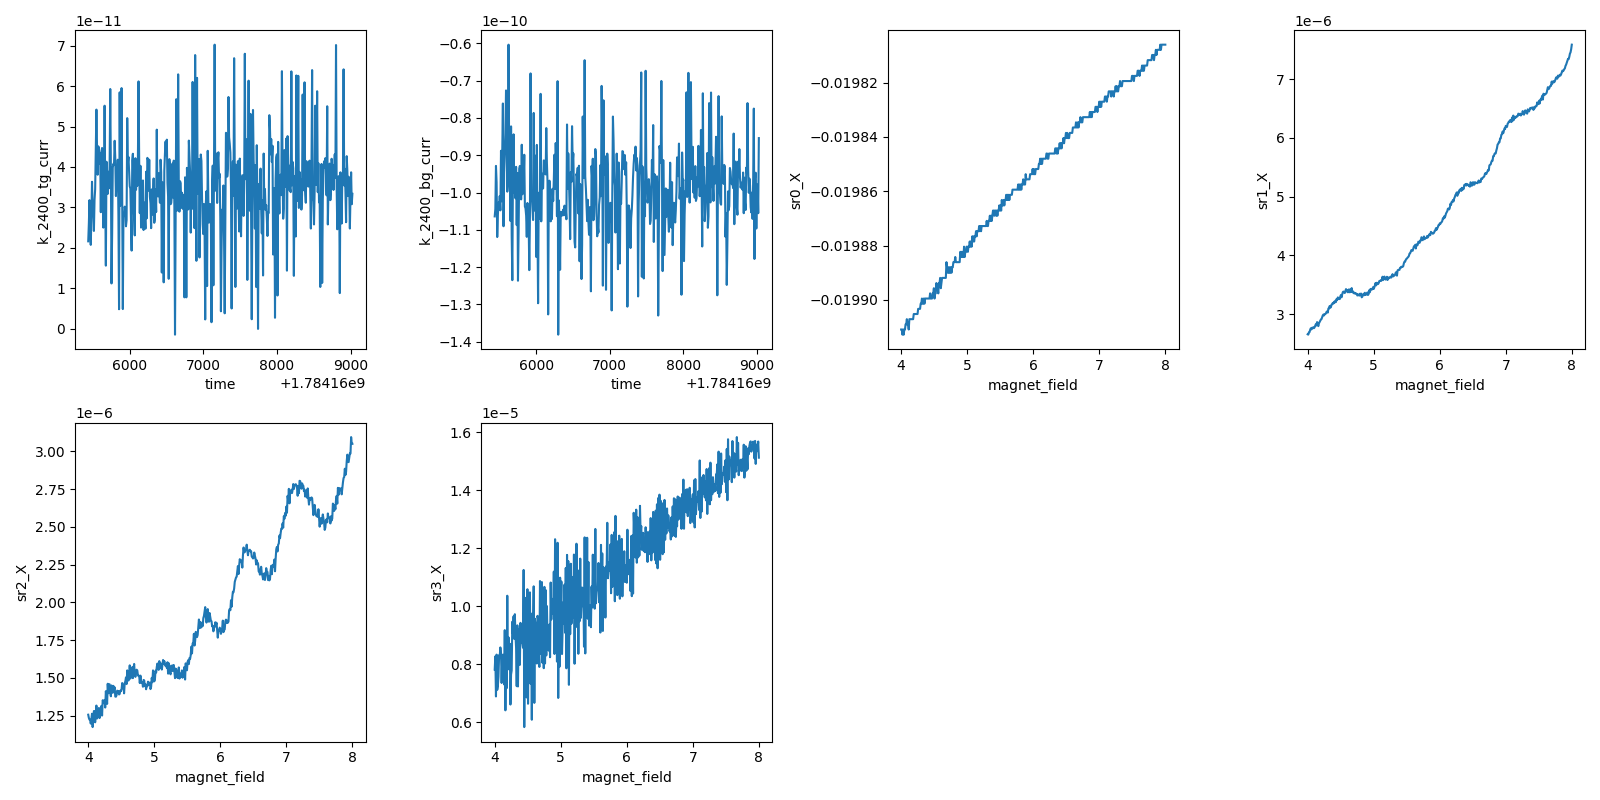

2026-07-15 19:30:24,767 [INFO] Completed in 0h 59m 51s


2026-07-15 19:30:24,768 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\10\data.tsv.gz


    rung 1 done: T was 25.087 K (now 26.436 K)
--> descending to 18.0 K (heaters off)


    descend   120 s  T= 26.261


    descend   240 s  T= 25.019


...

      780 s  T= 19.351  T_vap= 17.818


      840 s  T= 19.332  T_vap= 17.819


      900 s  T= 19.314  T_vap= 17.820


ladder exit: heaters off, gates parked, T=19.314 K, B=+4.003 T


RuntimeError: timeout: 18.0 K not settled in 900 s (T=19.314)

In [30]:
# === Cell B v4 (descend-catch): LK ladder 25 -> base (logfile guard 90 s; directional vap guard) ===
def logfile_fresh(max_age_s=90):
    paths = [p for p in _VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
    age = time.time() - max(os.path.getmtime(p) for p in paths)
    assert age < max_age_s, f"T_sample logfile stale ({age:.0f} s) — lakeshore worker dead?"

# (v3 ladder body — identical to v2 below)
from sharpelab_nb.gates import calc_gate_voltages

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both + settle-verify (logfile). Vaporizer guard is directional:
    fault only on runaway heating (Tv > start+2 AND Tv > target+2)."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1800)
    Tv_start = T_vaporizer()
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges=({heater.sample_range()},{heater.vaporizer_range()}), "
          f"tol={tol*1e3:.0f} mK, Tv_start={Tv_start:.2f}")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert not (Tv > Tv_start + 2 and Tv > target + 2), \
            f"vaporizer RUNAWAY: T_vap={Tv:.2f} K (start {Tv_start:.2f}, target {target})"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

_B0 = magnet.field()
print(f"precheck: T={T_sample():.3f} K (drifting down from 50), B={_B0:+.3f} T, Vsi={dc205.voltage():+.3f}")
assert abs(dc205.voltage()) < 1e-3
logfile_fresh()

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
k_tg.volt(vtg_t); k_bg.volt(vbg_t)
print(f"electron point set: Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

RUNGS = [25.0, 18.0, 14.0, 10.0, 7.0, 5.0, 3.0, None]
N_PTS = 421

try:
    for i, rung in enumerate(RUNGS):
        if rung is not None:
            # descend with heaters OFF (fast), catch 0.2 K below, lift + hold
            if T_sample() > rung + 0.3:
                heater.off('both')
                print(f"--> descending to {rung} K (heaters off)")
                t0d = time.time()
                while T_sample() > rung - 0.2:
                    interruptible_sleep(10)
                    logfile_fresh()
                    if int(time.time() - t0d) % 120 < 10:
                        print(f"    descend {time.time()-t0d:5.0f} s  T={T_sample():7.3f}")
                    if time.time() - t0d > 3600:
                        raise RuntimeError(f"descent to {rung} K timed out (T={T_sample():.3f})")
                print(f"    passed {rung} K after {time.time()-t0d:.0f} s — catching")
            settle = set_T_verified(rung)
        else:
            heater.off('both')
            print("--> heaters OFF, settling to base (<=1.6 K)")
            t0 = time.time()
            while T_sample() > 1.6:
                interruptible_sleep(30)
                logfile_fresh()
                if time.time() - t0 > 3600:
                    raise RuntimeError(f"base not reached in 60 min (T={T_sample():.3f})")
            settle = time.time() - t0
        T_now = T_sample()

        down = (i % 2 == 0)
        B_vec = np.linspace(8.0, 4.0, N_PTS) if down else np.linspace(4.0, 8.0, N_PTS)

        s = sweep.AsyncStation(meas_config)
        s.add_comment('temperature-dependence')
        s.add_comment(f'LK ladder rung {i+1}/{len(RUNGS)}: T = {T_now:.3f} K '
                      f'({"base" if rung is None else str(rung)+" K set"}), electron n = +6e12, D = 0 '
                      f'({vtg_t:.3f}, {vbg_t:.3f}); B {B_vec[0]:.0f}->{B_vec[-1]:.0f} T uniform 9.5 mT; '
                      f'I_bias=20 nA, sens fixed across ladder, settle {settle:.0f} s, cal run 4')
        s.fp(T_sample)
        s.fp(k_tg.volt).fp(k_tg.curr)
        s.fp(k_bg.volt).fp(k_bg.curr)
        s.plot('time', k_tg.curr)
        s.plot('time', k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.sweep(magnet.field, B_vec, delay=1.2)
        print(f"    rung {i+1} done: T was {T_now:.3f} K (now {T_sample():.3f} K)")
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print(f"ladder exit: heaters off, gates parked, T={T_sample():.3f} K, B={magnet.field():+.3f} T")


### Cell B v5 — ladder rungs 2–8 (hover acceptance; rung 1 = run 10 already taken)

Rung 2 exposed the untuned sample-loop PID (driver TODO): a post-catch set_both step overshoots ~+1.4 K and then relaxes bath-limited (~0.015 K/min) — tolerance-based settling can never pass at the tighter low-T tolerances. Rung 1 in fact ran in this hover state (T = 26.60 ± 0.29 K, recorded per point — valid data). **v5 acceptance matches the physics need (stability, not accuracy)**: after descend-catch + set_both, accept when T spread < 0.1 K over 90 s within [nominal − 0.5, nominal + 3] K; the sweep's fp'd T is the LK fit axis; rung labels are nominal only. Sweep direction now derived from the live field (start at the nearer endpoint — restart-robust). RUNGS = 18, 14, 10, 7, 5, 3, base. Everything else identical.


precheck: T=18.079 K (drifting down from 50), B=+4.003 T, Vsi=+0.000


electron point set: Vtg +2.840, Vbg +2.223
--> set_both(18.0, 0.99) + hover accept: band [17.5,21.0] K, spread<0.1 K/90s


       60 s  T= 18.026  T_vap= 17.162


      120 s  T= 18.042  T_vap= 17.827
    HOVER-ACCEPTED at T=18.042 K (nominal 18.0) in 120 s
2026-07-15 19:58:08,244 [INFO] Starting sweep with ID 11


2026-07-15 19:58:08,245 [INFO] Minimum duration 0h 8m 25s


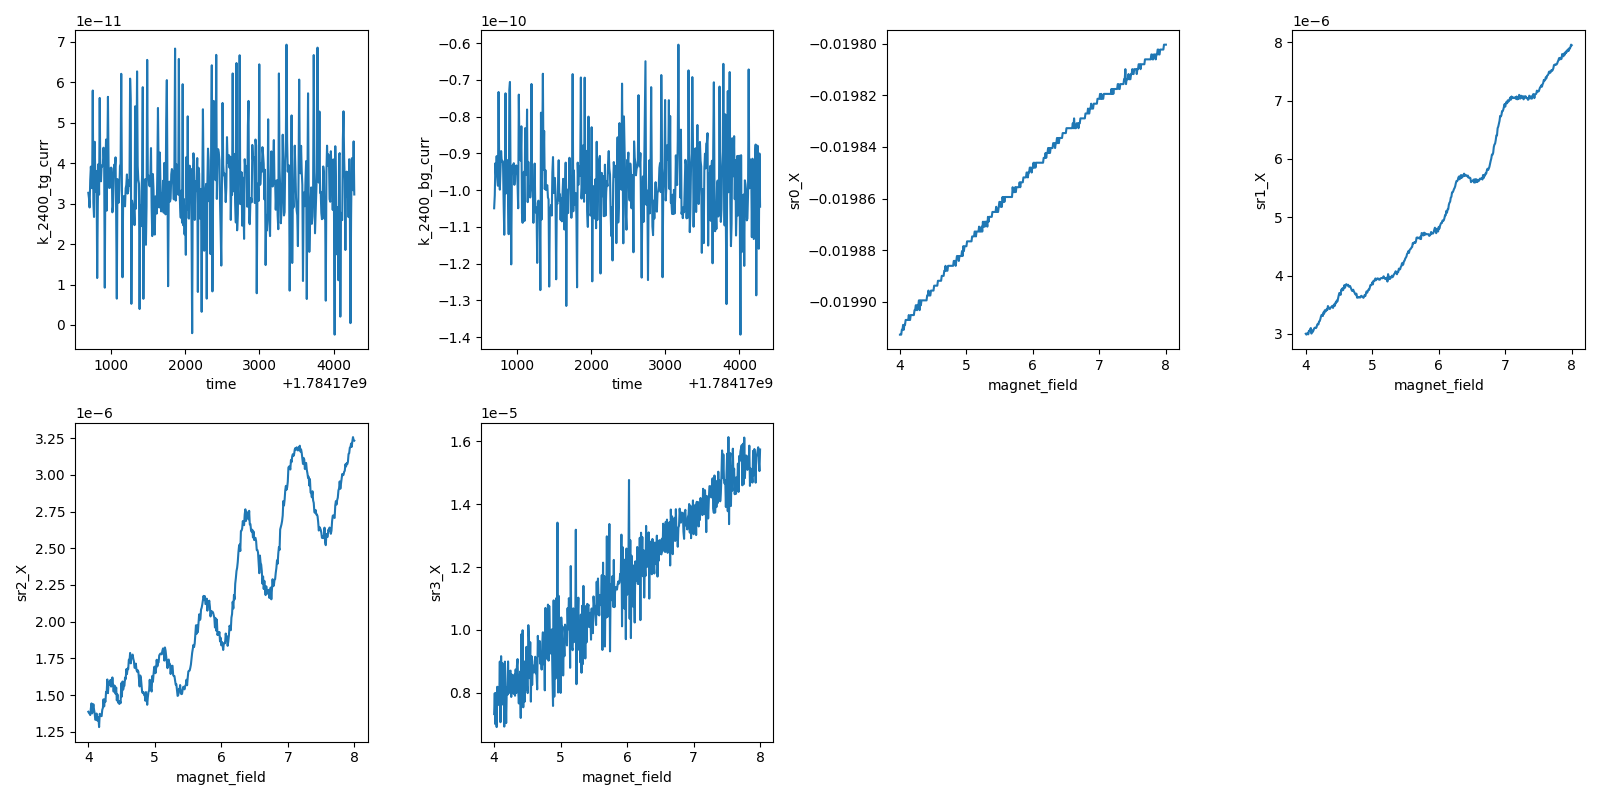

2026-07-15 20:58:00,850 [INFO] Completed in 0h 59m 51s


2026-07-15 20:58:00,851 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\11\data.tsv.gz


    rung 1 done: T was 18.042 K (now 19.047 K)
--> descending to 14.0 K (heaters off)


    descend    10 s  T= 19.047


    descend   120 s  T= 17.925


...

       75 s  T= 14.071  T_vap= 13.873


      195 s  T= 14.763  T_vap= 13.863


      240 s  T= 14.879  T_vap= 13.862


    HOVER-ACCEPTED at T=14.907 K (nominal 14.0) in 285 s
2026-07-15 21:06:45,891 [INFO] Starting sweep with ID 12


2026-07-15 21:06:45,892 [INFO] Minimum duration 0h 8m 25s


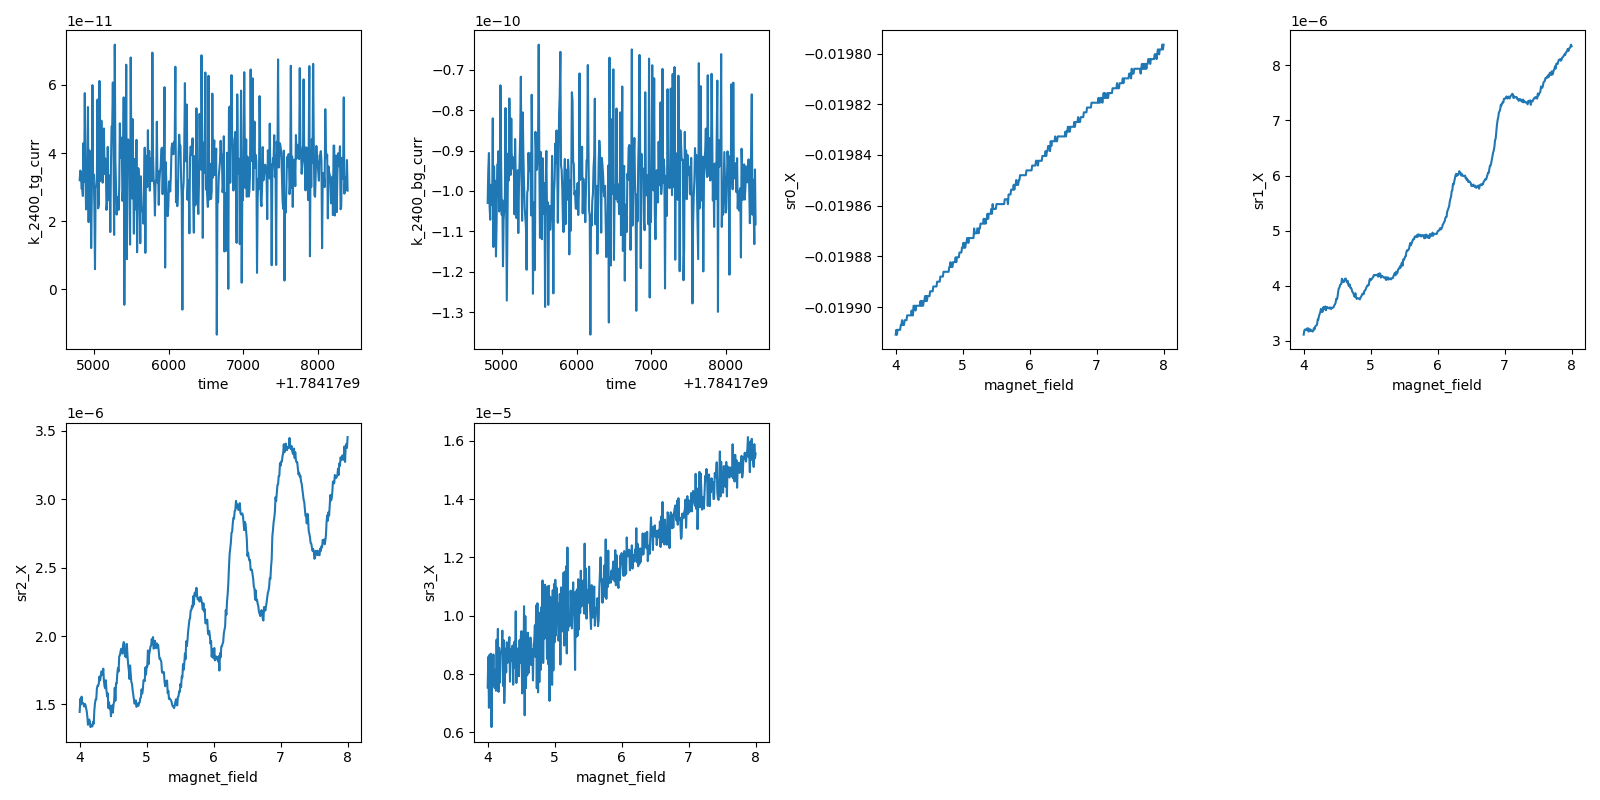

2026-07-15 22:06:36,213 [INFO] Completed in 0h 59m 49s


2026-07-15 22:06:36,213 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\12\data.tsv.gz


    rung 2 done: T was 14.907 K (now 14.826 K)
--> descending to 10.0 K (heaters off)


    descend    10 s  T= 14.826


    descend   120 s  T= 13.150


...

       60 s  T= 10.279  T_vap=  9.911


      120 s  T= 10.707  T_vap=  9.890


      180 s  T= 10.783  T_vap=  9.894


    HOVER-ACCEPTED at T=10.783 K (nominal 10.0) in 195 s
2026-07-15 22:12:31,273 [INFO] Starting sweep with ID 13


2026-07-15 22:12:31,274 [INFO] Minimum duration 0h 8m 25s


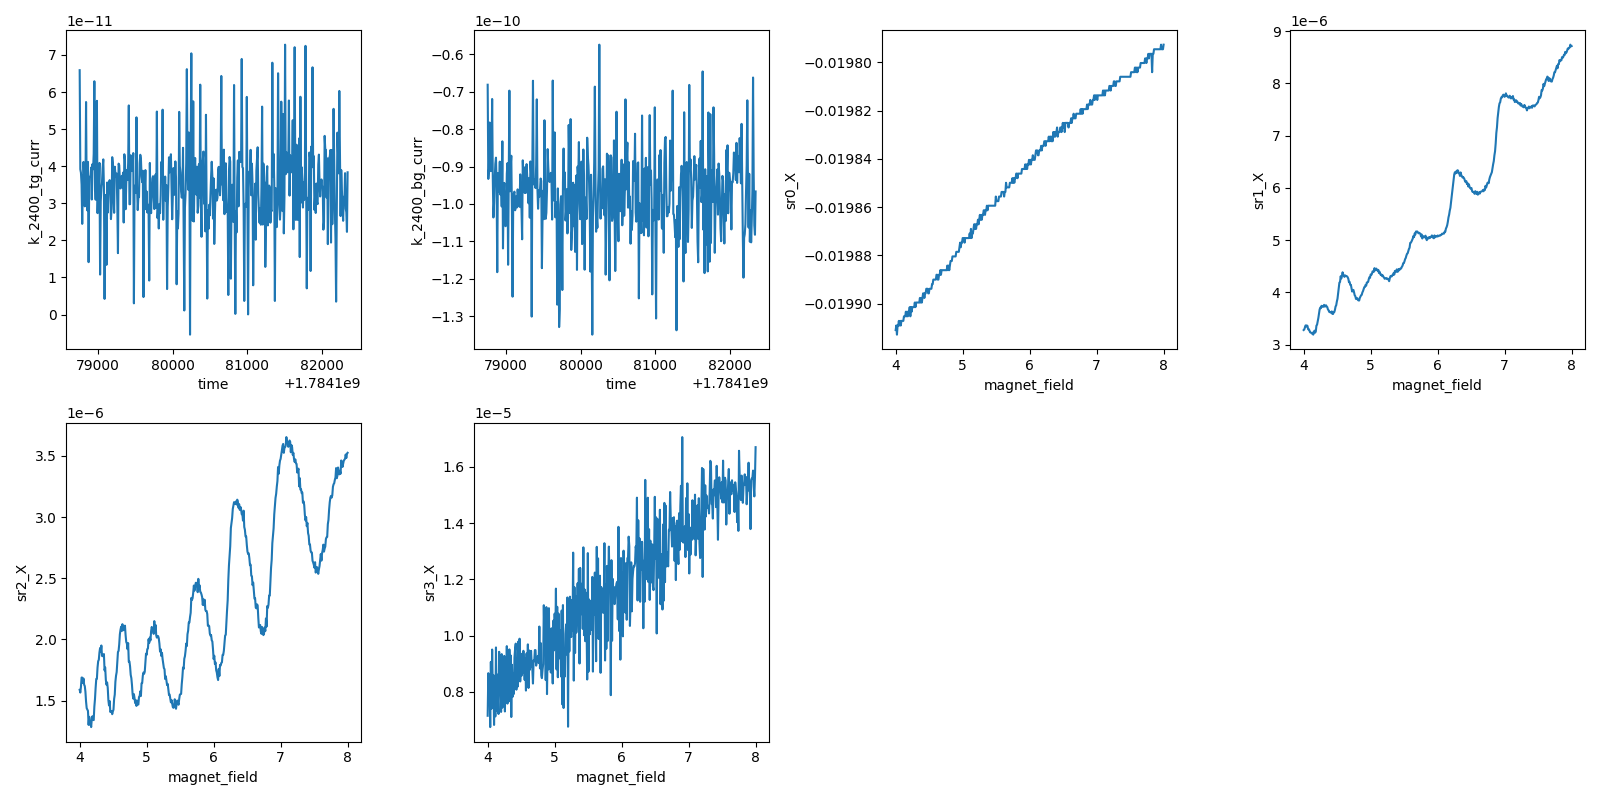

2026-07-15 23:12:23,278 [INFO] Completed in 0h 59m 51s


2026-07-15 23:12:23,279 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\13\data.tsv.gz


    rung 3 done: T was 10.783 K (now 10.595 K)
--> descending to 7.0 K (heaters off)


    descend   120 s  T=  4.796
    passed 7.0 K after 120 s — catching
--> set_both(7.0, 0.99) + hover accept: band [6.5,10.0] K, spread<0.1 K/90s


       15 s  T=  4.796  T_vap=  1.066


      180 s  T=  7.441  T_vap=  6.941


    HOVER-ACCEPTED at T=7.441 K (nominal 7.0) in 195 s
2026-07-15 23:17:38,352 [INFO] Starting sweep with ID 14


2026-07-15 23:17:38,354 [INFO] Minimum duration 0h 8m 25s


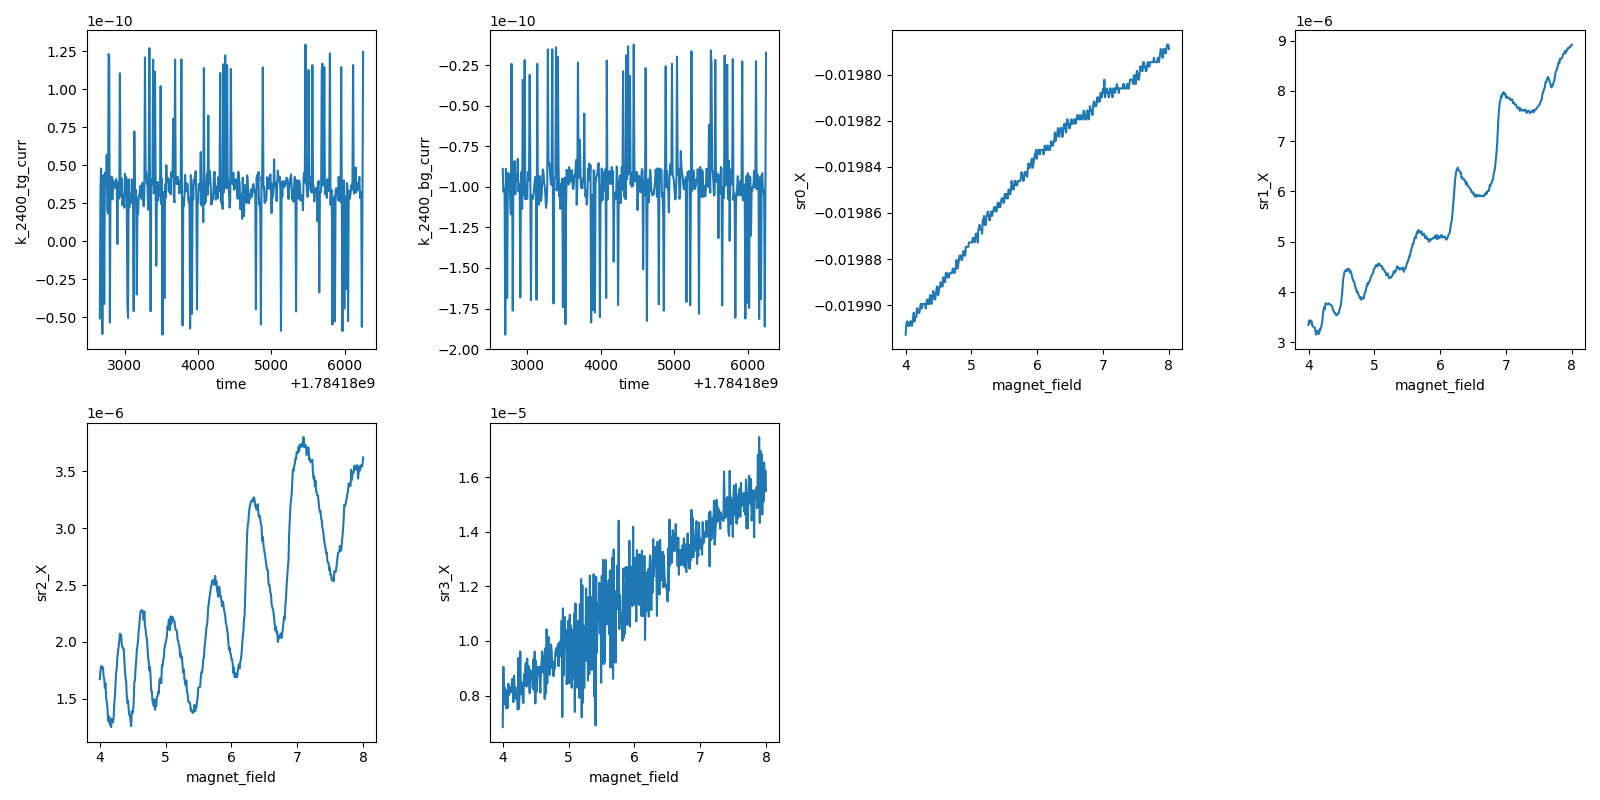

2026-07-16 00:17:30,960 [INFO] Completed in 0h 59m 51s


2026-07-16 00:17:30,961 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\14\data.tsv.gz


    rung 4 done: T was 7.441 K (now 7.453 K)
--> descending to 5.0 K (heaters off)


    passed 5.0 K after 60 s — catching
--> set_both(5.0, 0.99) + hover accept: band [4.5,8.0] K, spread<0.1 K/90s


       15 s  T=  4.389  T_vap=  1.089


       60 s  T=  5.298  T_vap=  4.898


      120 s  T=  5.378  T_vap=  4.937


    HOVER-ACCEPTED at T=5.378 K (nominal 5.0) in 135 s
2026-07-16 00:20:46,031 [INFO] Starting sweep with ID 15


2026-07-16 00:20:46,033 [INFO] Minimum duration 0h 8m 25s


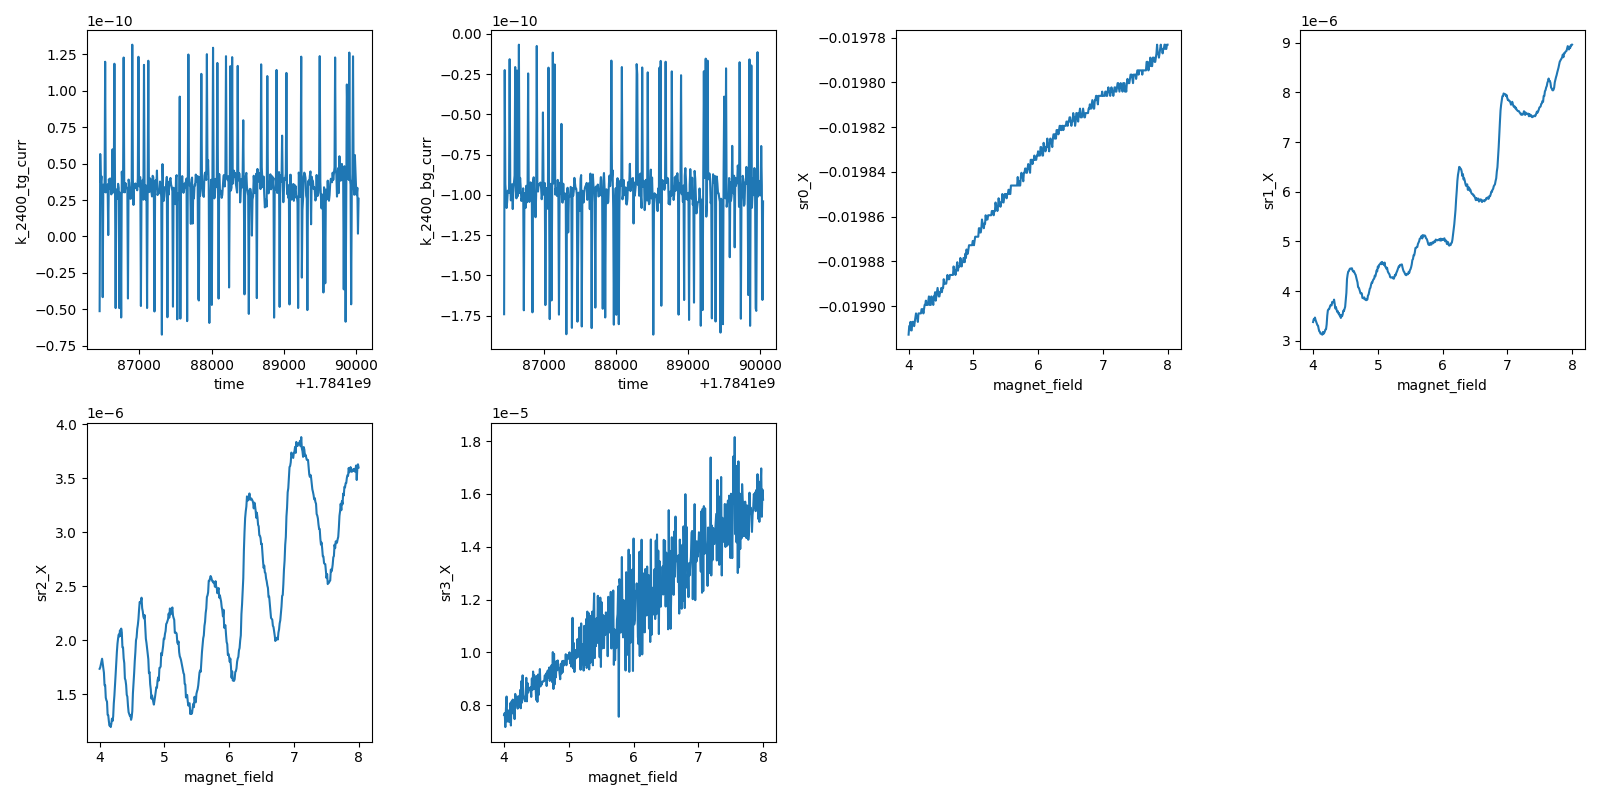

2026-07-16 01:20:37,852 [INFO] Completed in 0h 59m 50s


2026-07-16 01:20:37,853 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\15\data.tsv.gz


    rung 5 done: T was 5.378 K (now 5.354 K)
--> descending to 3.0 K (heaters off)


    descend    10 s  T=  5.339


    passed 3.0 K after 70 s — catching
--> set_both(3.0, 0.99) + hover accept: band [2.5,6.0] K, spread<0.1 K/90s


    HOVER-ACCEPTED at T=3.287 K (nominal 3.0) in 135 s
2026-07-16 01:24:02,906 [INFO] Starting sweep with ID 16


2026-07-16 01:24:02,907 [INFO] Minimum duration 0h 8m 25s


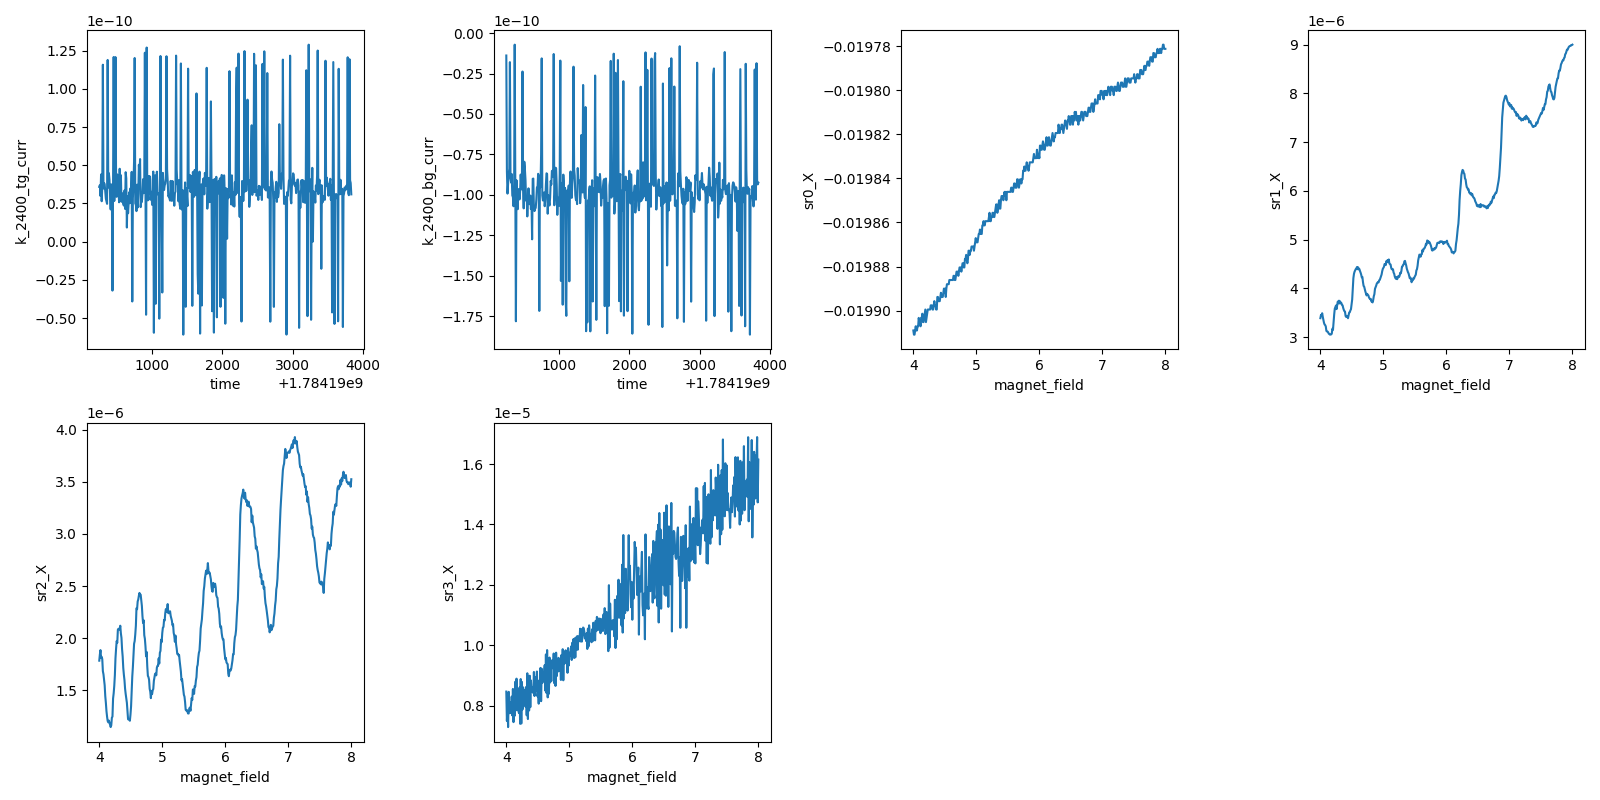

2026-07-16 02:23:55,378 [INFO] Completed in 0h 59m 51s


2026-07-16 02:23:55,379 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\16\data.tsv.gz


    rung 6 done: T was 3.287 K (now 3.308 K)
--> heaters OFF, settling to base (<=1.6 K)


2026-07-16 02:24:55,412 [INFO] Starting sweep with ID 17


2026-07-16 02:24:55,412 [INFO] Minimum duration 0h 8m 25s


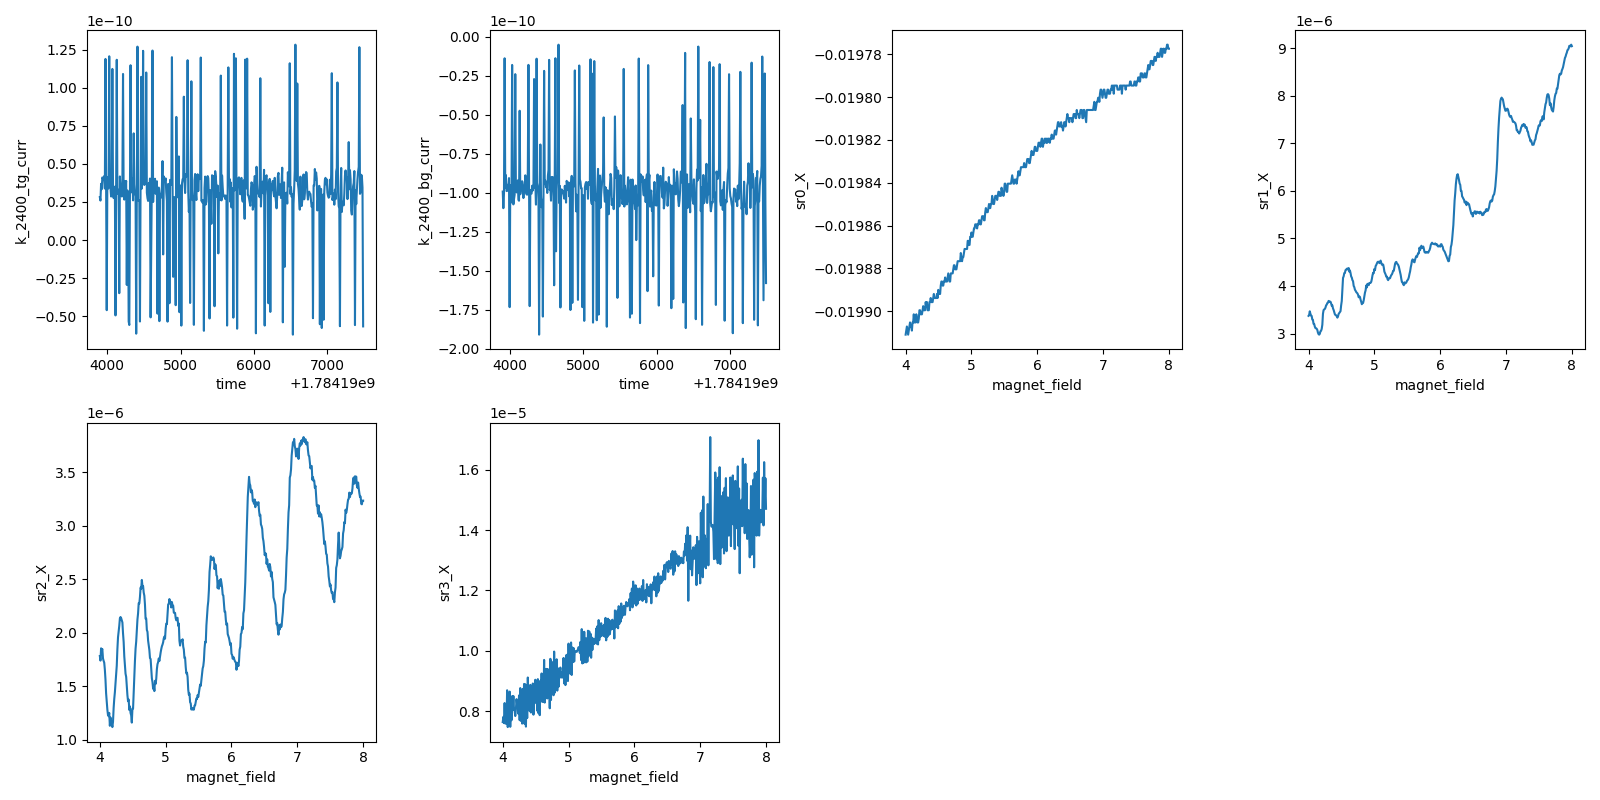

2026-07-16 03:24:48,164 [INFO] Completed in 0h 59m 51s


2026-07-16 03:24:48,165 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714.2-QC0426\data\17\data.tsv.gz


    rung 7 done: T was 1.481 K (now 1.279 K)


ladder exit: heaters off, gates parked, T=1.279 K, B=+8.004 T


In [31]:
# === Cell B v5 (hover acceptance; rungs 2-8): LK ladder 25 -> base (logfile guard 90 s; directional vap guard) ===
def logfile_fresh(max_age_s=90):
    paths = [p for p in _VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
    age = time.time() - max(os.path.getmtime(p) for p in paths)
    assert age < max_age_s, f"T_sample logfile stale ({age:.0f} s) — lakeshore worker dead?"

# (v3 ladder body — identical to v2 below)
from sharpelab_nb.gates import calc_gate_voltages

def hover_at(target, band=(-0.5, 3.0), spread=0.10, window_s=90, timeout_s=1200, poll_s=15):
    """set_both already/now engaged; accept quasi-stationary T near nominal.
    Returns (elapsed, T_at_accept). Directional vaporizer guard retained."""
    Tv_start = T_vaporizer()
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99) + hover accept: band [{target+band[0]:.1f},{target+band[1]:.1f}] K, spread<{spread} K/{window_s}s")
    t0, hist = time.time(), []
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        hist.append((time.time(), T))
        hist = [h for h in hist if h[0] > time.time() - window_s]
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert not (Tv > Tv_start + 2 and Tv > target + 2), f"vaporizer RUNAWAY: T_vap={Tv:.2f}"
        Ts = [h[1] for h in hist]
        if (len(hist) >= 4 and max(Ts) - min(Ts) < spread
                and target + band[0] <= T <= target + band[1]):
            print(f"    HOVER-ACCEPTED at T={T:.3f} K (nominal {target}) in {el:.0f} s")
            return el, T
        if el > timeout_s:
            raise RuntimeError(f"hover at {target} K not reached in {timeout_s} s (T={T:.3f})")

def set_T_verified(target, hold_s=60, timeout_s=None, poll_s=10):
    """set_both + settle-verify (logfile). Vaporizer guard is directional:
    fault only on runaway heating (Tv > start+2 AND Tv > target+2)."""
    tol = max(0.05, 0.005 * target)
    timeout_s = timeout_s or (900 if target < 20 else 1800)
    Tv_start = T_vaporizer()
    heater.set_both(target, ratio=0.99)
    print(f"--> set_both({target}, 0.99): ranges=({heater.sample_range()},{heater.vaporizer_range()}), "
          f"tol={tol*1e3:.0f} mK, Tv_start={Tv_start:.2f}")
    t0, ok_since = time.time(), None
    while True:
        interruptible_sleep(poll_s)
        logfile_fresh()
        el, T, Tv = time.time() - t0, T_sample(), T_vaporizer()
        if int(el) % 60 < poll_s:
            print(f"    {el:5.0f} s  T={T:7.3f}  T_vap={Tv:7.3f}")
        assert not (Tv > Tv_start + 2 and Tv > target + 2), \
            f"vaporizer RUNAWAY: T_vap={Tv:.2f} K (start {Tv_start:.2f}, target {target})"
        if abs(T - target) <= tol:
            ok_since = ok_since or time.time()
            if time.time() - ok_since >= hold_s:
                print(f"    SETTLED {target} K in {el:.0f} s (T_vap={Tv:.3f})")
                return el
        else:
            ok_since = None
        if el > timeout_s:
            raise RuntimeError(f"timeout: {target} K not settled in {timeout_s} s (T={T:.3f})")

_B0 = magnet.field()
print(f"precheck: T={T_sample():.3f} K (drifting down from 50), B={_B0:+.3f} T, Vsi={dc205.voltage():+.3f}")
assert abs(dc205.voltage()) < 1e-3
logfile_fresh()

C_TG, C_BG, N_OFF = 1.7027e-3, 2.1751e-3, -0.0365
vtg_t, vbg_t = calc_gate_voltages(+6.0, 0.0, C_TG, C_BG, n_offset=N_OFF)
sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5); sr0.sensitivity(5e-2)
k_tg.volt(vtg_t); k_bg.volt(vbg_t)
print(f"electron point set: Vtg {vtg_t:+.3f}, Vbg {vbg_t:+.3f}")

RUNGS = [18.0, 14.0, 10.0, 7.0, 5.0, 3.0, None]   # rung 1 (25 K) = run 10, done
N_PTS = 421

try:
    for i, rung in enumerate(RUNGS):
        if rung is not None:
            # descend with heaters OFF (fast), catch 0.2 K below, lift + hold
            if T_sample() > rung + 0.3:
                heater.off('both')
                print(f"--> descending to {rung} K (heaters off)")
                t0d = time.time()
                while T_sample() > rung - 0.2:
                    interruptible_sleep(10)
                    logfile_fresh()
                    if int(time.time() - t0d) % 120 < 10:
                        print(f"    descend {time.time()-t0d:5.0f} s  T={T_sample():7.3f}")
                    if time.time() - t0d > 3600:
                        raise RuntimeError(f"descent to {rung} K timed out (T={T_sample():.3f})")
                print(f"    passed {rung} K after {time.time()-t0d:.0f} s — catching")
            settle, T_accept = hover_at(rung)
        else:
            heater.off('both')
            print("--> heaters OFF, settling to base (<=1.6 K)")
            t0 = time.time()
            while T_sample() > 1.6:
                interruptible_sleep(30)
                logfile_fresh()
                if time.time() - t0 > 3600:
                    raise RuntimeError(f"base not reached in 60 min (T={T_sample():.3f})")
            settle = time.time() - t0
        T_now = T_sample()

        down = magnet.field() > 6.0   # start at the nearer endpoint (restart-robust)
        B_vec = np.linspace(8.0, 4.0, N_PTS) if down else np.linspace(4.0, 8.0, N_PTS)

        s = sweep.AsyncStation(meas_config)
        s.add_comment('temperature-dependence')
        s.add_comment(f'LK ladder rung {i+1}/{len(RUNGS)}: T = {T_now:.3f} K '
                      f'({"base" if rung is None else str(rung)+" K set"}), electron n = +6e12, D = 0 '
                      f'({vtg_t:.3f}, {vbg_t:.3f}); B {B_vec[0]:.0f}->{B_vec[-1]:.0f} T uniform 9.5 mT; '
                      f'I_bias=20 nA, sens fixed across ladder, settle {settle:.0f} s, cal run 4')
        s.fp(T_sample)
        s.fp(k_tg.volt).fp(k_tg.curr)
        s.fp(k_bg.volt).fp(k_bg.curr)
        s.plot('time', k_tg.curr)
        s.plot('time', k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.sweep(magnet.field, B_vec, delay=1.2)
        print(f"    rung {i+1} done: T was {T_now:.3f} K (now {T_sample():.3f} K)")
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print(f"ladder exit: heaters off, gates parked, T={T_sample():.3f} K, B={magnet.field():+.3f} T")


## HERA — park: magnet to 0 T (ladder complete; session handoff)

In [32]:
print(f'B before: {magnet.field():+.4f} T')
magnet.field(0.0)
print(f'parked: B={magnet.field():+.4f} T, T={T_sample():.3f} K, Vtg={k_tg.volt():+.3f}, Vbg={k_bg.volt():+.3f}, Vsi={dc205.voltage():+.3f}, heater ranges=({heater.sample_range()},{heater.vaporizer_range()})')

B before: +8.0033 T


parked: B=-0.0002 T, T=1.181 K, Vtg=+0.000, Vbg=+0.000, Vsi=+0.000, heater ranges=(0,0)
